# Grammar Scoring Engine — data exploration, transcription and model

**Goal:** understand the data *before* preprocessing or modelling, so every later decision (what to clean, which features to build, how to validate) rests on what the recordings actually look like.

**Scope:** this notebook has three parts. **Part 1 (sections 1-10)** explores the data: labels, file integrity, audio format, signal quality and pause structure. **Part 2 (sections 11-14)** acts on what Part 1 found: it cleans the audio and turns every clip into a transcript with a time stamp on every word. **Part 3 (sections 15-19)** builds the features, trains and validates the regression model, and writes the submission file. Each section starts by saying why it exists and what each code cell does.

**The three things to know** (full list in section 10):

1. **The 37 clips labelled 0 are not "worst grammar".** They are one batch of noise-covered recordings, found only in train. Left in, they make any validation score look much better than it is.
2. **Test is mostly 45-second clips; train is mostly 60-second clips**, and the two lengths are scored differently. Validation has to account for that.
3. **Audio statistics alone say little about the score.** The transcript has to carry this task.

**From Part 2** (section 14): Whisper's own confidence in each word is the strongest signal found so far (correlation +0.62 with the score). Fillers and pauses, however, cannot be read from the transcripts.

**From Part 3** (section 19): the final model predicts the human score with a cross-validated error (RMSE) of **0.63** points and a correlation of **0.78**. Always guessing the average gives an error of 1.01. The predictions for the 216 test clips are in `submission.csv`.

| Section | Question it answers |
|---|---|
| 1 | Are the CSVs and audio files complete and consistent? |
| 2 | What does the target (grammar score) look like? |
| 3 | What format and length are the recordings? |
| 4 | How clean is the audio: loudness, noise, clipping, silence, pauses? |
| 5 | What are the clips labelled 0? |
| 6 | Does the test set look like the training set? |
| 7 | Which audio properties relate to the score? |
| 8 | What do low / mid / high scoring clips look and sound like? |
| 9 | Which clips need special handling? |
| 10 | Findings and what they change in the pipeline |
| 11 | Clean the audio: what do we change before transcription, and what do we leave alone? |
| 12 | Transcribe with Whisper: what did each speaker actually say? |
| 13 | Are the transcripts good enough to build a grammar model on? |
| 14 | Findings of Part 2 and what comes next |
| 15 | Features: how does each clip become a row of numbers? |
| 16 | Validation: how do we measure the model honestly? |
| 17 | Which model has the lowest error? |
| 18 | Final model, test predictions and the submission file |
| 19 | Findings of Part 3, limits and next improvements |

Per-clip features, cleaned audio and transcripts are cached in `shl-hiring-assessment-2026/working/eda/`, so a second run takes seconds.

## 0. Setup

**Why we need it:** every later section uses the same libraries, the same folders and the same chart style, so they are defined once here.

- **Cell 1 (imports and paths):** loads the libraries and builds every path from the notebook's own folder, so the project still runs if the folder is moved. It stops with a clear message if the dataset is missing, instead of failing later with a confusing error.
- **Cell 2 (chart style):** fixes one look for all charts (train = blue, test = orange) so they can be compared at a glance. `save` keeps a PNG of each figure for the report. `split_hist` draws train and test as a *share* of clips, because train is about 3.5 times larger and raw counts would mislead.

In [1]:
import hashlib, json, os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from scipy import stats
from joblib import Parallel, delayed
from IPython.display import Audio, display

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50, "display.width", 180, "display.precision", 3)

# ---- Paths are relative to this notebook, so the project folder can be moved ----
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "shl-hiring-assessment-2026" / "Dataset_Final"
WORK_DIR = PROJECT_DIR / "shl-hiring-assessment-2026" / "working"
EDA_DIR  = WORK_DIR / "eda"
FIG_DIR  = EDA_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

assert (DATA_DIR / "train.csv").exists(), f"Dataset not found at {DATA_DIR} - open this notebook from the project root"
print("Data:", DATA_DIR)
print("Outputs:", EDA_DIR)

Data: C:\SSHL\shl-hiring-assessment-2026\Dataset_Final
Outputs: C:\SSHL\shl-hiring-assessment-2026\working\eda


In [2]:
# ---- One visual language for every chart: train = blue, test = orange ----
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
BLUE_DARK, BLUE_LIGHT, BLUE_WASH = "#184f95", "#86b6ef", "#cde2fb"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
SPLIT_COLOR = {"train": BLUE, "test": ORANGE}
SEQ = LinearSegmentedColormap.from_list("seq_blue", [SURFACE, BLUE_WASH, "#6da7ec", BLUE, "#0d366b"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.labelsize": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "ytick.major.size": 0, "xtick.major.size": 3,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.8,
})

def save(fig, name):
    # Keep a PNG of every figure for the report, then show it inline.
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

def split_hist(ax, df, col, bins, xlabel, title=None):
    # Train vs test as share-of-clips per bin (the two splits differ in size, so raw counts would mislead).
    for split in ["train", "test"]:
        v = df.loc[df["split"] == split, col].dropna().clip(bins[0], bins[-1])
        w = np.full(len(v), 1 / max(len(v), 1))
        ax.hist(v, bins=bins, weights=w, histtype="stepfilled", color=SPLIT_COLOR[split], alpha=0.12)
        ax.hist(v, bins=bins, weights=w, histtype="step", color=SPLIT_COLOR[split], lw=1.6, label=f"{split} (n={len(v)})")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel(xlabel)
    if title: ax.set_title(title)

## 1. Tables and file integrity

Before reading any audio: do the CSVs agree with the folders, and with each other?

**What each code cell does and why**

- **Cell 1 (load the tables):** reads `train.csv`, `test.csv` and `sample_submission.csv` and counts rows, empty cells and repeated filenames. It is the cheapest check there is, and every later step trusts these tables.
- **Cell 2 (cross-check files and tables):** compares the filenames in each CSV with the audio files on disk, and the CSVs with each other. A missing or mismatched file found now costs nothing; found in the middle of a long transcription run it costs the run.

In [3]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df  = pd.read_csv(DATA_DIR / "test.csv")
sub_df   = pd.read_csv(DATA_DIR / "sample_submission.csv")

for name, df in [("train.csv", train_df), ("test.csv", test_df), ("sample_submission.csv", sub_df)]:
    print(f"{name:<22} rows={len(df):>4} | columns={list(df.columns)} | null cells={int(df.isna().sum().sum())} "
          f"| duplicate filenames={int(df['filename'].duplicated().sum())} | label values={df['label'].nunique()}")
display(train_df.head())

train.csv              rows= 769 | columns=['filename', 'label'] | null cells=0 | duplicate filenames=0 | label values=10
test.csv               rows= 216 | columns=['filename', 'label'] | null cells=0 | duplicate filenames=0 | label values=1
sample_submission.csv  rows= 204 | columns=['filename', 'label'] | null cells=0 | duplicate filenames=0 | label values=1


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


In [4]:
train_files = {p.name for p in (DATA_DIR / "train").iterdir()}
test_files  = {p.name for p in (DATA_DIR / "test").iterdir()}
tr_names, te_names, sub_names = set(train_df["filename"]), set(test_df["filename"]), set(sub_df["filename"])

checks = pd.DataFrame([
    ["train.csv rows without an audio file",            len(tr_names - train_files)],
    ["train audio files not listed in train.csv",       len(train_files - tr_names)],
    ["test.csv rows without an audio file",             len(te_names - test_files)],
    ["test audio files not listed in test.csv",         len(test_files - te_names)],
    ["filenames used in BOTH train.csv and test.csv",   len(tr_names & te_names)],
    ["sample_submission rows",                          len(sub_df)],
    ["sample_submission filenames that are in test.csv", len(sub_names & te_names)],
    ["sample_submission filenames that are in train.csv", len(sub_names & tr_names)],
    ["sample_submission filenames found in neither",    len(sub_names - te_names - tr_names)],
], columns=["check", "count"])
display(checks)

file_id = lambda s: s.str.extract(r"(\d+)")[0].astype(int)
for name, df in [("train", train_df), ("test", test_df), ("sample_submission", sub_df)]:
    ids = file_id(df["filename"])
    print(f"{name:<18} audio ids {ids.min()}-{ids.max()} ({len(ids)} files, {'contiguous' if ids.max() - ids.min() + 1 == len(ids) else 'sparse'})")

,check,count
0,train.csv rows without an audio file,0
1,train audio files not listed in train.csv,0
2,test.csv rows without an audio file,0
3,test audio files not listed in test.csv,0
4,filenames used in BOTH train.csv and test.csv,212
5,sample_submission rows,204
6,sample_submission filenames that are in test.csv,25
7,sample_submission filenames that are in train.csv,105
8,sample_submission filenames found in neither,99


train              audio ids 0-5073 (769 files, sparse)
test               audio ids 0-215 (216 files, contiguous)
sample_submission  audio ids 13-1329 (204 files, sparse)


**What this shows**

- Every CSV row has its audio file and every audio file has a row. No nulls, no duplicate rows.
- **212 filenames exist in both the train and the test folder, but they are different recordings** (section 4 confirms no two clips share identical audio). A filename alone is not a unique key: always keep `split` next to it and never merge train and test tables on `filename`.
- **`sample_submission.csv` does not correspond to `test.csv`.** It has 204 rows against 216 test clips, only 25 of its filenames are in `test.csv`, and 99 match no file at all. Use it for the column format only (`filename,label`) and build the real submission from `test.csv`.

## 2. The target: grammar score

The label is a mean opinion score on a 0–5 scale. Its shape decides how we stratify folds, whether to treat this as regression, and what a "do nothing" baseline scores.

**What each code cell does and why**

- **Cell 1 (score chart):** counts the clips at each score. A chart shows gaps and spikes that a mean or a standard deviation would hide.
- **Cell 2 (baselines):** computes the error of two "do nothing" predictions (always the mean, always the median). A model is only worth something if it beats them, so we need these numbers before training anything.

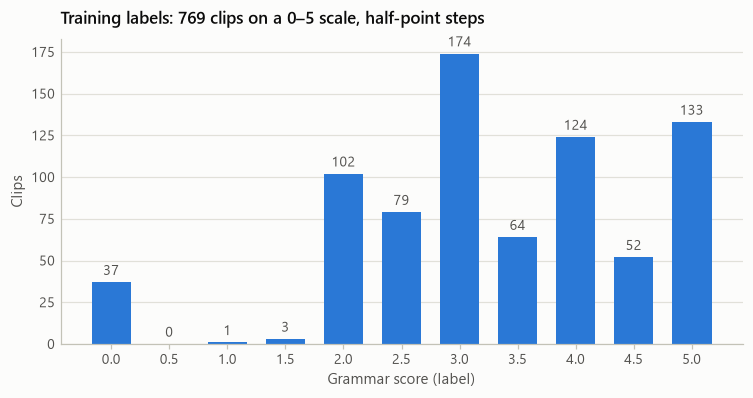

In [5]:
y = train_df["label"]
grid = np.arange(0, 5.5, 0.5)                      # every value a half-point 0-5 scale allows
counts = y.value_counts().reindex(grid, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(grid, counts.values, width=0.34, color=BLUE)
for x, c in zip(grid, counts.values):
    ax.text(x, c + counts.max() * 0.015, str(c), ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xticks(grid)
ax.set_xlabel("Grammar score (label)"); ax.set_ylabel("Clips")
ax.set_title(f"Training labels: {len(y)} clips on a 0–5 scale, half-point steps")
save(fig, "01_label_distribution")

In [6]:
whole = (y % 1 == 0)
label_stats = {
    "n": int(len(y)), "mean": float(y.mean()), "median": float(y.median()), "std": float(y.std(ddof=0)),
    "share_whole_number": float(whole.mean()), "n_score_0": int((y == 0).sum()),
    "n_between_0.5_and_1.5": int(y.between(0.5, 1.5).sum()),
    "baseline_rmse_predict_mean": float(y.std(ddof=0)),
    "baseline_mae_predict_median": float((y - y.median()).abs().mean()),
}
print(f"mean {label_stats['mean']:.2f} | median {label_stats['median']:.1f} | std {label_stats['std']:.2f}")
print(f"whole-number scores: {whole.mean():.0%} of clips | half-point scores: {1 - whole.mean():.0%}")
print(f"score 0: {label_stats['n_score_0']} clips ({(y == 0).mean():.1%}) | scores 0.5-1.5: {label_stats['n_between_0.5_and_1.5']} clips")
print(f"largest class / smallest non-empty class: {counts.max()} / {counts[counts > 0].min()}")
print(f"\nBaselines any model must beat:")
print(f"  always predict the mean   -> RMSE {label_stats['baseline_rmse_predict_mean']:.3f} (Pearson undefined)")
print(f"  always predict the median -> MAE  {label_stats['baseline_mae_predict_median']:.3f}")

mean 3.31 | median 3.0 | std 1.24
whole-number scores: 74% of clips | half-point scores: 26%
score 0: 37 clips (4.8%) | scores 0.5-1.5: 4 clips
largest class / smallest non-empty class: 174 / 1

Baselines any model must beat:
  always predict the mean   -> RMSE 1.238 (Pearson undefined)
  always predict the median -> MAE  0.987


**What this shows**

- In practice the scale runs from **2 to 5**. Only 4 clips sit between 0.5 and 1.5, and the 37 clips at exactly 0 are a separate case (section 5).
- **74 % of labels are whole numbers.** Half-points are what appears when two ratings one point apart are averaged, so the labels probably carry about half a point of rater disagreement. That is a hypothesis; this data cannot confirm it.
- The target is ordered and close to continuous, so regression is the natural framing, with predictions clipped to 0–5.
- A model has to beat RMSE 1.24 (always predict the mean). Section 5 shows why that baseline is misleadingly easy to beat.

## 3. Audio format and duration

Read from the file headers only (no decoding), so this is instant. It tells us whether resampling / channel mixing is needed and whether clips are the expected 45–60 s.

**What each code cell does and why**

- **Cell 1 (file headers):** reads sample rate, channels, encoding and duration of every file into one table, `meta`, with one row per clip. It tells us which preprocessing steps are really needed.
- **Cell 2 (clip length):** compares clip lengths in train and test, as a chart and as a table. Length matters because anything we count (words, pauses) grows with it.

In [7]:
meta = pd.concat([train_df.assign(split="train"), test_df.assign(split="test")], ignore_index=True)
meta.loc[meta["split"] == "test", "label"] = np.nan          # -1 is a placeholder, not a score
meta["path"] = [str(DATA_DIR / s / f) for s, f in zip(meta["split"], meta["filename"])]

def header_info(path):
    try:
        i = sf.info(path)
        return dict(sr=i.samplerate, channels=i.channels, subtype=i.subtype, duration=i.duration,
                    size_mb=os.path.getsize(path) / 1e6, readable=True)
    except Exception:
        return dict(readable=False)

meta = pd.concat([meta, pd.DataFrame([header_info(p) for p in meta["path"]])], axis=1)

fmt = meta.groupby("split", sort=False).agg(
    clips=("filename", "size"), unreadable=("readable", lambda s: int((~s).sum())),
    sample_rates=("sr", lambda s: sorted(s.dropna().astype(int).unique())),
    channels=("channels", lambda s: sorted(s.dropna().astype(int).unique())),
    encoding=("subtype", lambda s: sorted(s.dropna().unique())),
    hours=("duration", lambda s: round(s.sum() / 3600, 2)), size_gb=("size_mb", lambda s: round(s.sum() / 1000, 2)))
display(fmt)
display(meta.groupby("split", sort=False)["duration"].describe().round(2))

,clips,unreadable,sample_rates,channels,encoding,hours,size_gb
split,,,,,,,
train,769,0,[16000],[1],[PCM_16],11.92,1.37
test,216,0,[16000],[1],[PCM_16],2.93,0.34


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,769.0,55.78,7.91,20.06,54.19,60.07,60.07,61.04
test,216.0,48.76,8.18,6.48,45.06,45.06,60.01,61.03


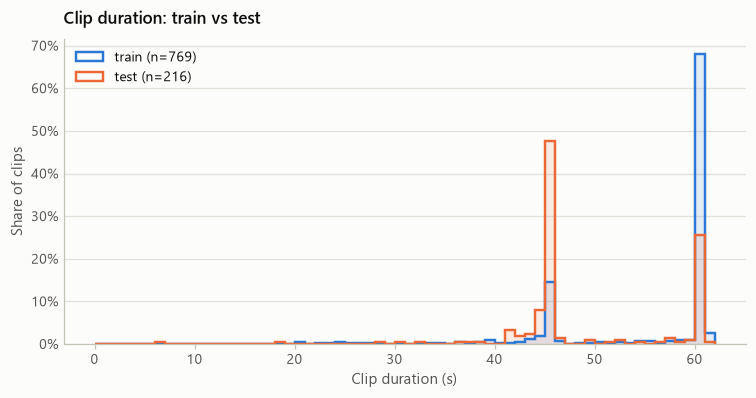

split,train,test,train %,test %
dur_bucket,,,,
< 20 s,0,2,0.0,0.9
20-40 s,30,6,3.9,2.8
40-50 s,152,141,19.8,65.3
50-58 s,27,8,3.5,3.7
>= 58 s,560,59,72.8,27.3


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
split_hist(ax, meta, "duration", np.arange(0, 63, 1), "Clip duration (s)", "Clip duration: train vs test")
ax.set_ylabel("Share of clips")
ax.legend(loc="upper left")
save(fig, "02_duration_train_vs_test")

DUR_BINS, DUR_NAMES = [0, 20, 40, 50, 58, 70], ["< 20 s", "20-40 s", "40-50 s", "50-58 s", ">= 58 s"]
meta["dur_bucket"] = pd.cut(meta["duration"], DUR_BINS, labels=DUR_NAMES, right=False)
bucket = pd.crosstab(meta["dur_bucket"], meta["split"])[["train", "test"]]
bucket_pct = (bucket / bucket.sum() * 100).round(1).add_suffix(" %")
display(pd.concat([bucket, bucket_pct], axis=1))

**What this shows**

- **Uniform format:** all 985 files are 16 kHz, mono, 16-bit PCM WAV and all open correctly. The resample / mono-mix step of the preprocessing pipeline has nothing to change (fine to keep as a guard).
- **Two clip lengths:** recordings are cut at about **45 s** or about **60 s**. Train is 73 % 60-second clips; **test is 65 % 45-second clips**. Section 6 shows this is the main difference between train and test.
- Test has 2 clips under 20 s (6.5 s and 18.6 s). Train has none shorter than 20 s, so those two are outside anything a model will have seen.

## 4. Signal-level features

Each file is decoded once and summarised. Thresholds are the **same ones the preprocessing notebook uses** (`trim top_db=35`, `split top_db=30`, pause ≥ 0.3 s, long pause ≥ 1 s, SNR measured after DC removal and edge trimming), so the numbers here predict what that pipeline will do.

| Group | Features | Why we look |
|---|---|---|
| Level | `rms_dbfs`, `peak`, `clip_ratio`, `dc_offset` | Is loudness normalisation needed? Any distorted recordings? |
| Noise | `snr_db`, `noise_floor_db`, `dyn_range_db` | How many clips would trigger noise reduction (SNR < 15 dB)? |
| Silence | `lead_silence_s`, `trail_silence_s`, `speech_ratio` | How much dead air is there to trim? Any empty recordings? |
| Pauses | `n_pauses`, `pauses_per_min`, `mean_pause_s`, `max_pause_s`, `long_pauses`, `mean_segment_s` | Fluency signal that raters hear |
| Spectrum | `centroid_hz`, `hf_ratio_db` | Separates speech from hiss; narrow-band recordings hurt ASR |

**What each code cell does and why**

- **Cell 1 (`signal_features`):** measures one clip. It is written as a function so the same code runs on every file, in parallel.
- **Cell 2 (run and cache):** applies it to all 985 clips on 8 processor cores and saves the result, so later runs load it in a second instead of decoding 15 hours of audio again. It then adds a few derived columns and checks that no two clips hold identical audio: a copy of a training clip inside the test set would leak its label.
- **Cell 3 (charts):** plots six of the measures for train against test, with a summary table underneath.

In [9]:
FRAME, HOP = 1024, 256                 # 64 ms window, 16 ms hop at 16 kHz
TRIM_DB, SPLIT_DB = 35, 30
MIN_PAUSE, LONG_PAUSE = 0.3, 1.0       # seconds

def signal_features(path):
    y, sr = sf.read(path, dtype="float32", always_2d=True)
    y = y.mean(axis=1)
    dur = len(y) / sr
    f = {"pcm_md5": hashlib.md5(y.tobytes()).hexdigest()}      # hash of the samples, ignores header differences

    # Level
    f["peak"] = float(np.abs(y).max())
    f["clip_ratio"] = float(np.mean(np.abs(y) >= 0.999))
    f["dc_offset"] = float(y.mean())
    f["rms_dbfs"] = float(20 * np.log10(np.sqrt(np.mean(y ** 2)) + 1e-10))
    frame_db = 20 * np.log10(librosa.feature.rms(y=y, frame_length=FRAME, hop_length=HOP)[0] + 1e-10)
    f["noise_floor_db"] = float(np.percentile(frame_db, 10))
    f["speech_level_db"] = float(np.percentile(frame_db, 95))

    # Edge silence: what trim_edges() would remove
    _, (start, end) = librosa.effects.trim(y, top_db=TRIM_DB)
    f["lead_silence_s"] = start / sr
    f["trail_silence_s"] = (len(y) - end) / sr

    # Speech / pause structure
    iv = librosa.effects.split(y, top_db=SPLIT_DB, frame_length=FRAME, hop_length=HOP)
    seg = (iv[:, 1] - iv[:, 0]) / sr
    gaps = (iv[1:, 0] - iv[:-1, 1]) / sr
    pauses = gaps[gaps >= MIN_PAUSE]
    f["speech_s"] = float(seg.sum())
    f["speech_ratio"] = float(seg.sum() / dur) if dur else 0.0
    f["n_pauses"] = int(len(pauses))
    f["pauses_per_min"] = float(len(pauses) / dur * 60) if dur else 0.0
    f["mean_pause_s"] = float(pauses.mean()) if len(pauses) else 0.0
    f["max_pause_s"] = float(pauses.max()) if len(pauses) else 0.0
    f["long_pauses"] = int((pauses >= LONG_PAUSE).sum())
    f["mean_segment_s"] = float(seg.mean()) if len(seg) else 0.0

    # SNR exactly as the preprocessing pipeline measures it: DC removal -> edge trim (+0.25 s pad) -> speech vs non-speech energy
    pad = int(0.25 * sr)
    yt = (y - y.mean())[max(0, start - pad): min(len(y), end + pad)]
    mask = np.zeros(len(yt), dtype=bool)
    for a, b in librosa.effects.split(yt, top_db=SPLIT_DB):
        mask[a:b] = True
    if mask.any() and (~mask).sum() >= 0.2 * sr:
        f["snr_db"] = float(10 * np.log10((np.mean(yt[mask] ** 2) + 1e-12) / (np.mean(yt[~mask] ** 2) + 1e-12)))
    else:
        f["snr_db"] = np.nan                                   # too little non-speech to estimate

    # Spectrum: average power spectrum of the whole clip
    psd = (np.abs(librosa.stft(y, n_fft=FRAME, hop_length=FRAME // 2)) ** 2).mean(axis=1) + 1e-20
    freqs = librosa.fft_frequencies(sr=sr, n_fft=FRAME)
    f["centroid_hz"] = float((freqs * psd).sum() / psd.sum())
    f["hf_ratio_db"] = float(10 * np.log10(psd[freqs >= 4000].sum() / psd.sum()))
    return f

In [10]:
FEAT_CSV = EDA_DIR / "audio_eda_features.csv"

if FEAT_CSV.exists() and len(pd.read_csv(FEAT_CSV, usecols=["filename"])) == len(meta):
    feats = pd.read_csv(FEAT_CSV)
    print(f"Loaded cached features for {len(feats)} clips from {FEAT_CSV.name}")
else:
    t0 = time.time()
    rows = Parallel(n_jobs=min(8, os.cpu_count()))(delayed(signal_features)(p) for p in meta["path"])
    feats = pd.concat([meta.drop(columns="dur_bucket"), pd.DataFrame(rows)], axis=1)
    feats.to_csv(FEAT_CSV, index=False)
    print(f"Decoded {len(feats)} clips in {time.time() - t0:.0f} s -> {FEAT_CSV.name}")

# ---- Derived columns (cheap, so not cached) ----
feats["file_id"] = file_id(feats["filename"])
feats["dur_bucket"] = pd.cut(feats["duration"], DUR_BINS, labels=DUR_NAMES, right=False)
feats["length_group"] = np.select([feats["duration"].between(40, 50, inclusive="left"), feats["duration"] >= 58], ["~45 s", "~60 s"], "other")
feats["edge_silence_s"] = feats["lead_silence_s"] + feats["trail_silence_s"]
feats["noise_floor_db"] = feats["noise_floor_db"].clip(lower=-96)             # below 16-bit resolution = digital silence
feats["dyn_range_db"] = feats["speech_level_db"] - feats["noise_floor_db"]    # loud frames vs quiet frames; defined for every clip
feats["no_silence_found"] = feats["speech_ratio"] >= 0.97                     # the energy detector saw (almost) no pause at all
train, test = feats[feats["split"] == "train"], feats[feats["split"] == "test"]

dup = feats[feats.duplicated("pcm_md5", keep=False)].sort_values("pcm_md5")
print(f"Clips whose audio samples are byte-identical to another clip: {len(dup)}")
if len(dup): display(dup[["split", "filename", "label", "duration", "pcm_md5"]])

Loaded cached features for 985 clips from audio_eda_features.csv
Clips whose audio samples are byte-identical to another clip: 0


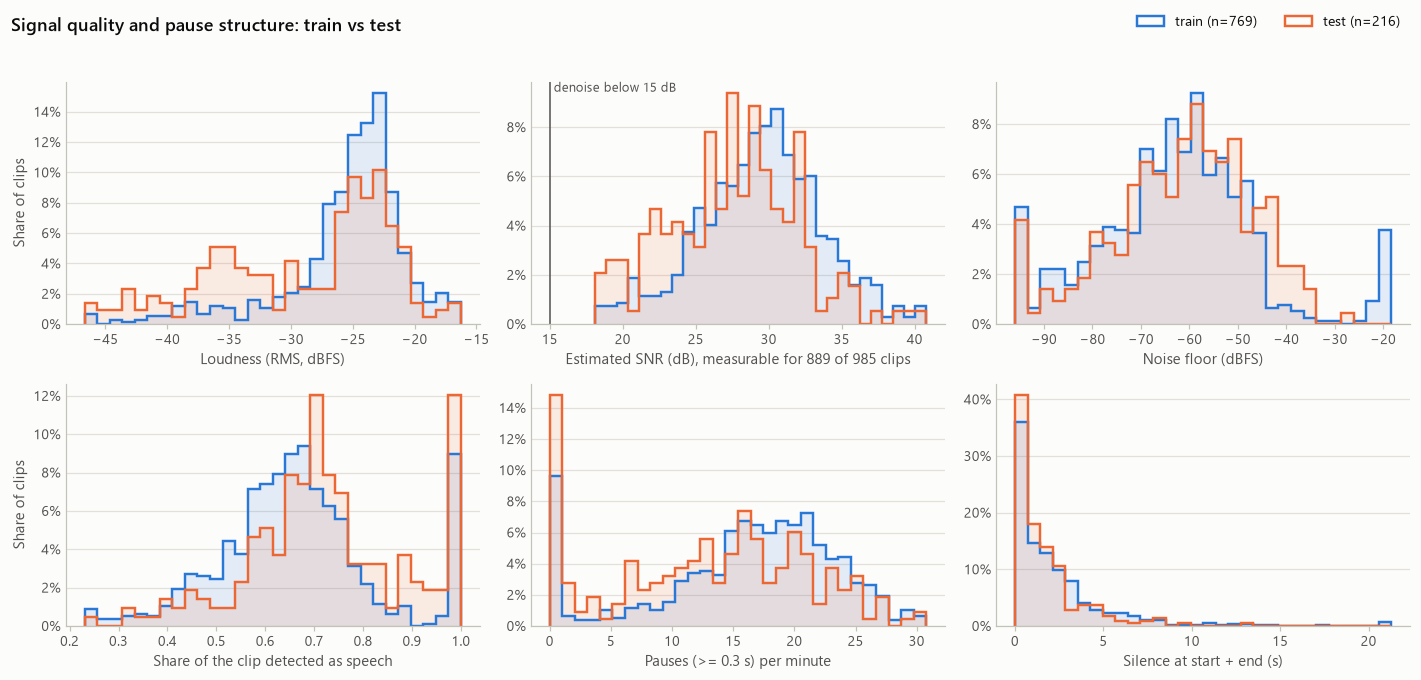

split,train,test
median_loudness_dbfs,-24.4,-26.1
loudness_spread_p5_to_p95_db,18,22.2
pct_quieter_than_minus_32_dbfs,10,34.3
clips_with_snr_below_15_db,1,0
clips_where_snr_is_not_measurable,72,24
pct_no_silence_found,9.1,13
median_edge_silence_s,1.41,1.06
pct_edge_silence_over_5_s,11.7,6.02
max_clipped_share_pct,0.0588,0.019
max_abs_dc_offset,0.00074,0.00207


In [11]:
SNR_THRESHOLD = 15.0     # the preprocessing notebook denoises clips below this

PANELS = [
    ("rms_dbfs",       "Loudness (RMS, dBFS)"),
    ("snr_db",         f"Estimated SNR (dB), measurable for {int(feats['snr_db'].notna().sum())} of {len(feats)} clips"),
    ("noise_floor_db", "Noise floor (dBFS)"),
    ("speech_ratio",   "Share of the clip detected as speech"),
    ("pauses_per_min", "Pauses (>= 0.3 s) per minute"),
    ("edge_silence_s", "Silence at start + end (s)"),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
for ax, (col, name) in zip(axes.ravel(), PANELS):
    lo, hi = feats[col].quantile([0.005, 0.995])
    split_hist(ax, feats, col, np.linspace(lo, hi, 31), name)
    if col == "snr_db":
        ax.axvline(SNR_THRESHOLD, color=INK2, lw=1)
        ax.text(SNR_THRESHOLD, ax.get_ylim()[1], " denoise below 15 dB", color=INK2, fontsize=8.5, va="top")
for ax in axes[:, 0]: ax.set_ylabel("Share of clips")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.0))
fig.suptitle("Signal quality and pause structure: train vs test", x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save(fig, "03_signal_quality_train_vs_test")

q = feats.groupby("split", sort=False).agg(
    median_loudness_dbfs=("rms_dbfs", "median"),
    loudness_spread_p5_to_p95_db=("rms_dbfs", lambda s: s.quantile(0.95) - s.quantile(0.05)),
    pct_quieter_than_minus_32_dbfs=("rms_dbfs", lambda s: (s < -32).mean() * 100),
    clips_with_snr_below_15_db=("snr_db", lambda s: (s < SNR_THRESHOLD).sum()),
    clips_where_snr_is_not_measurable=("snr_db", lambda s: s.isna().sum()),
    pct_no_silence_found=("no_silence_found", lambda s: s.mean() * 100),
    median_edge_silence_s=("edge_silence_s", "median"),
    pct_edge_silence_over_5_s=("edge_silence_s", lambda s: (s > 5).mean() * 100),
    max_clipped_share_pct=("clip_ratio", lambda s: s.max() * 100),
    max_abs_dc_offset=("dc_offset", lambda s: s.abs().max()))
display(q.T.style.format("{:.3g}"))

**What this shows**

- **Loudness varies widely:** about 18 dB between the 5th and 95th percentile in train and 22 dB in test. Test is quieter overall: 34 % of test clips sit below −32 dBFS against 10 % of train. Loudness normalisation is doing real work here.
- **The SNR rule would fire on 1 clip out of 985.** That is a blind spot of the estimator, not evidence that the audio is clean. It measures noise in the silent parts of a clip, and for 96 clips (72 train, 24 test) it finds no silent part at all. In that case `estimate_snr` in the preprocessing notebook returns 40 dB ("assume clean"), so the noisiest recordings in the dataset would be logged as the cleanest and skip noise reduction. `noise_floor_db` and `dyn_range_db` are defined for every clip and are the better quality measures.
- The same problem produces the spikes at **speech share = 100 %** and **0 pauses per minute**: for 9 % of train and 13 % of test clips, energy-based detection reports non-stop speech. Pause features built on an energy threshold cannot be trusted on those clips.
- **Clipping and DC offset are negligible.** No clip has more than 0.06 % clipped samples, and the largest DC offset is 0.002. DC removal is harmless but not needed.
- **Edge silence** is usually about 1 s, but 12 % of train clips (6 % of test) carry more than 5 s, so trimming is worth keeping.

## 5. What are the clips labelled 0?

Section 2 showed 37 clips at exactly 0 and almost nothing between 0 and 2. Before treating 0 as "the worst grammar", check whether those clips are ordinary recordings. The table gives min / median / max of each measure for the score-0 clips, the other training clips, and the test clips.

**What each code cell does and why**

- **Cell 1 (profile and rule):** puts the score-0 clips next to the other clips on a few measures, then writes down a simple rule that describes them and counts how many clips match it in train and in test.
- **Cell 2 (scatter plot):** draws every clip on the two measures used by the rule, so the separation can be seen and not just asserted.
- **Cell 3 (effect on validation):** scores a fake "model" that only spots these clips. It shows how much of a good-looking validation score could come from them alone.

In [12]:
PROFILE = {"file_id": "File id (audio_<id>.wav)", "duration": "Clip duration (s)", "rms_dbfs": "Loudness (RMS, dBFS)",
           "noise_floor_db": "Noise floor (dBFS)", "dyn_range_db": "Loud vs quiet frames (dB)",
           "centroid_hz": "Spectral centroid (Hz)", "hf_ratio_db": "Energy above 4 kHz (dB rel. total)",
           "speech_ratio": "Share of clip detected as speech", "pauses_per_min": "Pauses per minute"}
groups = {f"train, score 0 (n={int((train['label'] == 0).sum())})": train[train["label"] == 0],
          f"train, score > 0 (n={int((train['label'] > 0).sum())})": train[train["label"] > 0],
          f"test (n={len(test)})": test}
profile = pd.concat({name: g[list(PROFILE)].agg(["min", "median", "max"]).T for name, g in groups.items()}, axis=1).rename(index=PROFILE)
display(profile.style.format("{:.4g}"))

# Two numbers are enough to describe that group: a loud noise floor AND a nearly flat (hiss-like) spectrum.
NOISE_FLOOR_MIN, HF_RATIO_MIN = -30.0, -8.0
feats["noise_bed"] = (feats["noise_floor_db"] > NOISE_FLOOR_MIN) & (feats["hf_ratio_db"] > HF_RATIO_MIN)
train, test = feats[feats["split"] == "train"], feats[feats["split"] == "test"]

print(f"Rule: noise floor > {NOISE_FLOOR_MIN:g} dBFS and energy above 4 kHz > {HF_RATIO_MIN:g} dB")
print(f"  train clips matching: {int(train['noise_bed'].sum())} -> their labels: {train.loc[train['noise_bed'], 'label'].value_counts().to_dict()}")
print(f"  train clips labelled 0 that do NOT match: {int(((train['label'] == 0) & ~train['noise_bed']).sum())}")
print(f"  test clips matching: {int(test['noise_bed'].sum())} of {len(test)}")

Rule: noise floor > -30 dBFS and energy above 4 kHz > -8 dB
  train clips matching: 37 -> their labels: {0.0: 37}
  train clips labelled 0 that do NOT match: 0
  test clips matching: 0 of 216


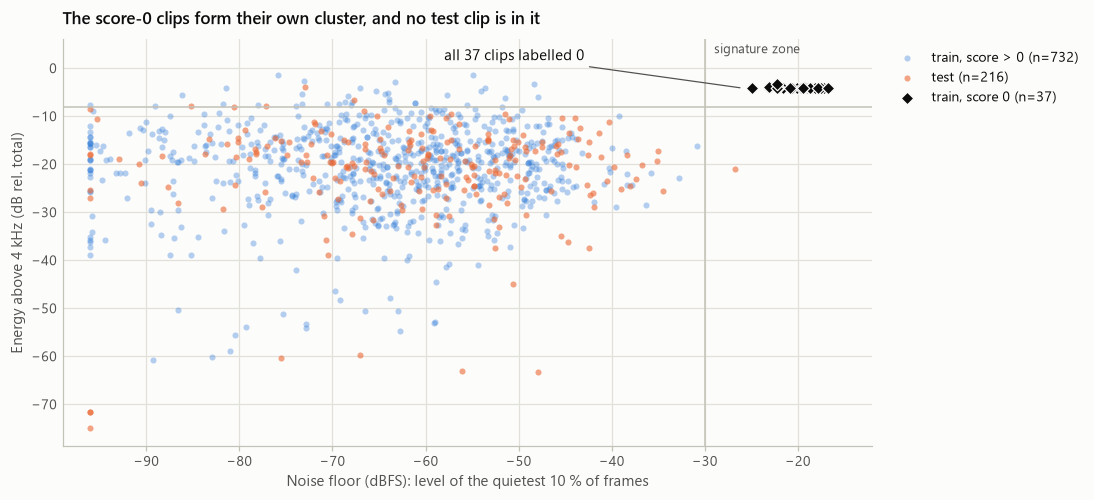

In [13]:
others, zeros = train[train["label"] > 0], train[train["label"] == 0]

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.scatter(others["noise_floor_db"], others["hf_ratio_db"], s=16, color=BLUE, alpha=0.35, linewidth=0, label=f"train, score > 0 (n={len(others)})")
ax.scatter(test["noise_floor_db"], test["hf_ratio_db"], s=16, color=ORANGE, alpha=0.6, linewidth=0, label=f"test (n={len(test)})")
ax.scatter(zeros["noise_floor_db"], zeros["hf_ratio_db"], s=34, color=INK, marker="D", edgecolor=SURFACE, linewidth=0.8, label=f"train, score 0 (n={len(zeros)})")
ax.axvline(NOISE_FLOOR_MIN, color=AXIS, lw=1); ax.axhline(HF_RATIO_MIN, color=AXIS, lw=1)
ax.set_xlim(-99, -12); ax.set_ylim(top=6)
ax.text(NOISE_FLOOR_MIN + 1, 5.2, "signature zone", fontsize=8.5, color=INK2, va="top")
ax.annotate(f"all {len(zeros)} clips labelled 0", xy=(zeros["noise_floor_db"].min() - 1, zeros["hf_ratio_db"].median()),
            xytext=(-58, 2.5), fontsize=9.5, color=INK, va="center", arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.grid(axis="x")
ax.set_xlabel("Noise floor (dBFS): level of the quietest 10 % of frames")
ax.set_ylabel("Energy above 4 kHz (dB rel. total)")
ax.set_title("The score-0 clips form their own cluster, and no test clip is in it")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save(fig, "04_score0_noise_signature")

In [14]:
# How good does a "model" look if all it can do is spot these clips?
y_true = train["label"].to_numpy()
y_scored = train.loc[~train["noise_bed"], "label"]
spotter = np.where(train["noise_bed"], 0.0, y_scored.mean())        # 0 for noise-bed clips, one constant for everything else
spotter_r = stats.pearsonr(y_true, spotter).statistic
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - b) ** 2)))

baselines = pd.DataFrame([
    [f"all {len(train)} training clips", "always the mean", np.nan, rmse(y_true, y_true.mean())],
    [f"all {len(train)} training clips", "noise spotter: 0 for noise-bed clips, one constant otherwise", spotter_r, rmse(y_true, spotter)],
    [f"the {len(y_scored)} clips with score > 0", "always the mean", np.nan, rmse(y_scored, y_scored.mean())],
], columns=["evaluated on", "prediction", "Pearson r", "RMSE"])
display(baselines.style.format({"Pearson r": "{:.2f}", "RMSE": "{:.3f}"}, na_rep="undefined"))

,evaluated on,prediction,Pearson r,RMSE
0,all 769 training clips,always the mean,undefined,1.238
1,all 769 training clips,"noise spotter: 0 for noise-bed clips, one constant otherwise",0.60,0.989
2,the 732 clips with score > 0,always the mean,undefined,1.014


**What this shows**

- **The 37 score-0 clips are one homogeneous batch, unlike anything else in the data.** Each has a loud, constant noise bed (noise floor about −19 dBFS, against −63 for other clips), a nearly flat spectrum (energy above 4 kHz between −4.2 and −3.2 dB in all 37), and only 3–5 dB between its loud and quiet frames (other clips: about 44 dB). They also sit in their own filename block, `audio_5037` to `audio_5073`, while every other training file is numbered below 785.
- The two-threshold rule (noise floor > −30 dBFS and high-frequency energy > −8 dB) selects exactly those 37 clips in train and nothing else. **It selects no test clip.**
- So in this dataset, label 0 behaves like a marker for a batch of noise-covered recordings, not like the low end of the grammar scale. For clips with ordinary audio the scale effectively starts at 2. Listen to the score-0 example in section 8 to hear what is left of the speech under the noise.
- **Why it matters for modelling:** a "model" that only spots these clips and outputs one constant for everything else reaches **Pearson r = 0.60** on the training set without knowing anything about grammar. Any cross-validation score that includes them will look far better than what the model can do on the test set, where no such clip exists. The honest baseline is the last row: RMSE 1.01 on the 732 clips with a real score.
- From here on, the analysis treats those 732 clips separately.

## 6. Does the test set look like the training set?

Validation only tells the truth if the training clips resemble the test clips. Three checks, all on clips with ordinary audio (the 37 noise-bed clips are left out, since section 5 showed they have no counterpart in test):

1. **Per feature:** Kolmogorov–Smirnov distance between train and test (0 = same distribution, 1 = no overlap), overall and inside each clip-length group.
2. **All features together (adversarial validation):** train a classifier to tell train clips from test clips. AUC near 0.5 means it cannot.
3. **Labels by clip length:** if 45-second and 60-second clips are scored differently, a different mix of lengths means a different score distribution in test.

**What each code cell does and why:** cell 1 runs check 1, cell 2 runs check 2, and cell 3 runs check 3. Cell 3 also looks at the mean score per block of filenames, to see whether the data was collected in batches.

In [15]:
FEATURES = {
    "duration": "Clip duration (s)", "speech_s": "Speech time (s)", "speech_ratio": "Share of clip detected as speech",
    "n_pauses": "Number of pauses", "pauses_per_min": "Pauses per minute", "mean_pause_s": "Mean pause length (s)",
    "max_pause_s": "Longest pause (s)", "long_pauses": "Pauses >= 1 s", "mean_segment_s": "Mean speech-run length (s)",
    "edge_silence_s": "Silence at start + end (s)", "rms_dbfs": "Loudness (RMS, dBFS)",
    "speech_level_db": "Speech level (dBFS)", "noise_floor_db": "Noise floor (dBFS)", "dyn_range_db": "Loud vs quiet frames (dB)",
    "snr_db": "Estimated SNR (dB)", "clip_ratio": "Clipped samples (share)", "centroid_hz": "Spectral centroid (Hz)",
    "hf_ratio_db": "Energy above 4 kHz (dB)",
}
LENGTH_DEPENDENT = ["duration", "speech_s", "n_pauses", "long_pauses"]     # grow with clip length by construction

real = feats[~feats["noise_bed"]]                                          # ordinary recordings only
real_train, real_test = real[real["split"] == "train"], real[real["split"] == "test"]
g45, g60 = real[real["length_group"] == "~45 s"], real[real["length_group"] == "~60 s"]

def ks(df, c):
    a, b = df.loc[df["split"] == "train", c].dropna(), df.loc[df["split"] == "test", c].dropna()
    return stats.ks_2samp(a, b).statistic

shift = pd.DataFrame([{
    "feature": name, "train median": real_train[c].median(), "test median": real_test[c].median(),
    "KS, all clips": ks(real, c), "KS, 45-s clips": ks(g45, c), "KS, 60-s clips": ks(g60, c),
} for c, name in FEATURES.items()]).sort_values("KS, all clips", ascending=False).reset_index(drop=True)
display(shift.style.format({"train median": "{:.3g}", "test median": "{:.3g}", "KS, all clips": "{:.2f}",
                            "KS, 45-s clips": "{:.2f}", "KS, 60-s clips": "{:.2f}"}))

,feature,train median,test median,"KS, all clips","KS, 45-s clips","KS, 60-s clips"
0,Clip duration (s),60.1,45.1,0.45,0.06,0.06
1,Pauses >= 1 s,3,1,0.33,0.13,0.24
2,Number of pauses,17,11,0.32,0.12,0.19
3,Longest pause (s),1.68,1.06,0.30,0.15,0.20
4,Speech level (dBFS),-18.2,-20.2,0.29,0.10,0.08
5,"Loudness (RMS, dBFS)",-24.6,-26.1,0.27,0.09,0.08
6,Share of clip detected as speech,0.649,0.714,0.27,0.14,0.18
7,Mean pause length (s),0.711,0.577,0.26,0.12,0.19
8,Pauses per minute,18,14,0.26,0.13,0.20
9,Loud vs quiet frames (dB),43.9,36.3,0.25,0.17,0.14


In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

def adversarial_auc(df, cols):
    X, is_test = df[cols].to_numpy(float), (df["split"] == "test").to_numpy(int)
    clf = HistGradientBoostingClassifier(max_depth=3, max_iter=150, learning_rate=0.05, random_state=SEED)
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    return roc_auc_score(is_test, cross_val_predict(clf, X, is_test, cv=cv, method="predict_proba")[:, 1])

rate_feats = [c for c in FEATURES if c not in LENGTH_DEPENDENT]
cases = [
    ("all clips",            "all audio features",          real, list(FEATURES)),
    ("all clips",            "clip duration only",          real, ["duration"]),
    ("all clips",            "length-independent features", real, rate_feats),
    ("45-second clips only", "length-independent features", g45,  rate_feats),
    ("60-second clips only", "length-independent features", g60,  rate_feats),
]
adv = pd.DataFrame([{
    "clips compared": who, "features given to the classifier": what,
    "train clips": int((d["split"] == "train").sum()), "test clips": int((d["split"] == "test").sum()),
    "train-vs-test AUC": adversarial_auc(d, cols),
} for who, what, d, cols in cases])
display(adv.style.format({"train-vs-test AUC": "{:.2f}"}))

,clips compared,features given to the classifier,train clips,test clips,train-vs-test AUC
0,all clips,all audio features,732,216,0.75
1,all clips,clip duration only,732,216,0.73
2,all clips,length-independent features,732,216,0.69
3,45-second clips only,length-independent features,149,141,0.48
4,60-second clips only,length-independent features,527,59,0.63


In [17]:
scored = real_train                                    # training clips with a real grammar score
GROUPS = ["~45 s", "~60 s", "other"]
by_len = scored.groupby("length_group")["label"].agg(clips="size", mean_score="mean", median_score="median").reindex(GROUPS)
by_len["median loudness (dBFS)"] = scored.groupby("length_group")["rms_dbfs"].median()
by_len["share of train"] = by_len["clips"] / len(scored)
by_len["share of test"] = real_test["length_group"].value_counts(normalize=True)
display(by_len.style.format({"mean_score": "{:.2f}", "median_score": "{:.1f}", "median loudness (dBFS)": "{:.1f}",
                             "share of train": "{:.0%}", "share of test": "{:.0%}"}))

s45, s60 = (scored.loc[scored["length_group"] == g, "label"] for g in GROUPS[:2])
reweighted = float((by_len["mean_score"] * by_len["share of test"]).sum())
print(f"45-second clips score {s60.mean() - s45.mean():.2f} points lower than 60-second clips on average "
      f"(Mann-Whitney p = {stats.mannwhitneyu(s45, s60).pvalue:.1e})")
print(f"Mean score of scored training clips: {scored['label'].mean():.2f} | re-weighted to the test mix of clip lengths: {reweighted:.2f}")

# Score level by filename block: are the files numbered in batches?
blocks = pd.cut(scored["file_id"], [0, 100, 216, 300, 400, 600, 800], right=False)
by_id = scored.groupby(blocks, observed=True).agg(clips=("label", "size"), share_45s=("length_group", lambda s: (s == "~45 s").mean()), mean_score=("label", "mean"))
by_id.index = [f"audio_{int(i.left)} to audio_{int(i.right) - 1}" for i in by_id.index]
display(by_id.rename_axis("training files").style.format({"share_45s": "{:.0%}", "mean_score": "{:.2f}"}))

,clips,mean_score,median_score,median loudness (dBFS),share of train,share of test
length_group,,,,,,
~45 s,149,3.06,3.0,-30.2,20%,65%
~60 s,527,3.58,3.5,-24.1,72%,27%
other,56,3.62,4.0,-26.2,8%,7%


45-second clips score 0.52 points lower than 60-second clips on average (Mann-Whitney p = 5.3e-08)
Mean score of scored training clips: 3.48 | re-weighted to the test mix of clip lengths: 3.25


,clips,share_45s,mean_score
training files,,,
audio_0 to audio_99,99,86%,2.94
audio_100 to audio_215,113,35%,3.27
audio_216 to audio_299,82,6%,3.85
audio_300 to audio_399,87,3%,4.24
audio_400 to audio_599,184,3%,2.93
audio_600 to audio_799,167,6%,3.97


**What this shows**

- **Train and test differ, and clip length is most of it.** A classifier tells them apart with AUC 0.75 using every feature, and already 0.73 from clip duration alone.
- **Inside the 45-second group, train and test are indistinguishable** (AUC 0.48). Inside the 60-second group the difference is small (AUC 0.63). So test is not a different kind of data. It is a different *mix*: 65 % 45-second clips, which are only 20 % of train.
- **That mix matters because the two lengths are scored differently.** 45-second clips average 3.06 against 3.58 for 60-second clips (Mann-Whitney p ≈ 5e-8), and they are recorded about 6 dB quieter. Re-weighting train to the test mix moves the expected mean score from 3.48 to about 3.25.
- Mean score also swings between filename blocks (2.9 to 4.2), so the data was collected in batches with different score levels. File id must not be used as a feature: test files are renumbered 0–215, so it would not carry over.
- **What to do:** stratify CV folds on length group as well as score; report validation metrics for the 45-second group on its own, because that is what most of the test set looks like; and express count features per minute (words per minute, pauses per minute), never as raw counts.

## 7. Which audio properties relate to the score?

Spearman rank correlation with the label on training clips. Each feature appears twice: on **all** clips, and on clips with a **score above 0**. The gap between the two dots is the distortion caused by the 37 noise-bed clips; the light dot is the one that says something about real scores.

These are acoustic features only. Grammar lives in the words, so weak correlations are expected here.

**What each code cell does and why**

- **Cell 1 (correlations):** one number per feature says how strongly it moves with the score. Computing it with and without the score-0 clips shows how much those clips distort the picture.
- **Cell 2 (box plots):** a correlation is a single number; the box plots show the shape behind it for the six strongest features.
- **Cell 3 (pauses by clip length):** repeats the correlation separately for 45-second and 60-second clips, because a pooled number can hide two opposite effects.

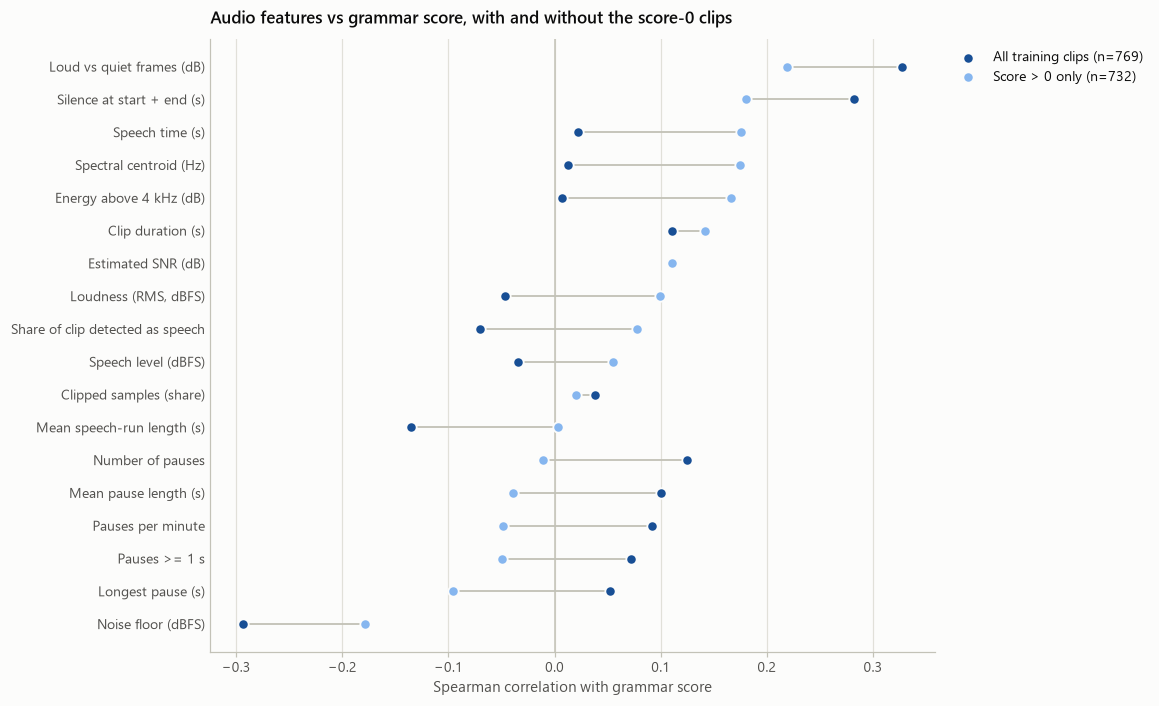

,feature,rho (all clips),rho (score > 0),"rho (score > 0, 60-s clips)","rho (score > 0, 45-s clips)"
0,Loud vs quiet frames (dB),+0.33,+0.22,+0.16,+0.23
1,Silence at start + end (s),+0.28,+0.18,+0.14,+0.20
2,Speech time (s),+0.02,+0.18,+0.22,-0.12
3,Spectral centroid (Hz),+0.01,+0.17,+0.20,+0.01
4,Energy above 4 kHz (dB),+0.01,+0.17,+0.21,+0.01
5,Clip duration (s),+0.11,+0.14,+0.01,+0.03
6,Estimated SNR (dB),+0.11,+0.11,+0.07,+0.18
7,"Loudness (RMS, dBFS)",-0.05,+0.10,+0.00,+0.18
8,Share of clip detected as speech,-0.07,+0.08,+0.22,-0.12
9,Speech level (dBFS),-0.03,+0.06,-0.06,+0.18


With n = 732, |rho| above about 0.07 is distinguishable from zero (p < 0.05). That does not make it useful.


In [18]:
rho = lambda df, c: stats.spearmanr(df[c], df["label"], nan_policy="omit").statistic
corr = pd.DataFrame([{
    "feature": name, "col": c, "rho (all clips)": rho(train, c), "rho (score > 0)": rho(scored, c),
    "rho (score > 0, 60-s clips)": rho(scored[scored["length_group"] == "~60 s"], c),
    "rho (score > 0, 45-s clips)": rho(scored[scored["length_group"] == "~45 s"], c),
} for c, name in FEATURES.items()]).sort_values("rho (score > 0)").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 0.33 * len(corr) + 1.3))
ypos = np.arange(len(corr))
ax.hlines(ypos, corr["rho (all clips)"], corr["rho (score > 0)"], color=AXIS, lw=1.2, zorder=1)
ax.scatter(corr["rho (all clips)"], ypos, s=46, color=BLUE_DARK, edgecolor=SURFACE, linewidth=1.2, zorder=2, label=f"All training clips (n={len(train)})")
ax.scatter(corr["rho (score > 0)"], ypos, s=46, color=BLUE_LIGHT, edgecolor=SURFACE, linewidth=1.2, zorder=3, label=f"Score > 0 only (n={len(scored)})")
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(ypos, corr["feature"])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Spearman correlation with grammar score")
ax.set_title("Audio features vs grammar score, with and without the score-0 clips")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save(fig, "05_feature_label_correlation")

display(corr.drop(columns="col").sort_values("rho (score > 0)", ascending=False).reset_index(drop=True)
        .style.format({c: "{:+.2f}" for c in corr.columns if c.startswith("rho")}))
print(f"With n = {len(scored)}, |rho| above about 0.07 is distinguishable from zero (p < 0.05). That does not make it useful.")

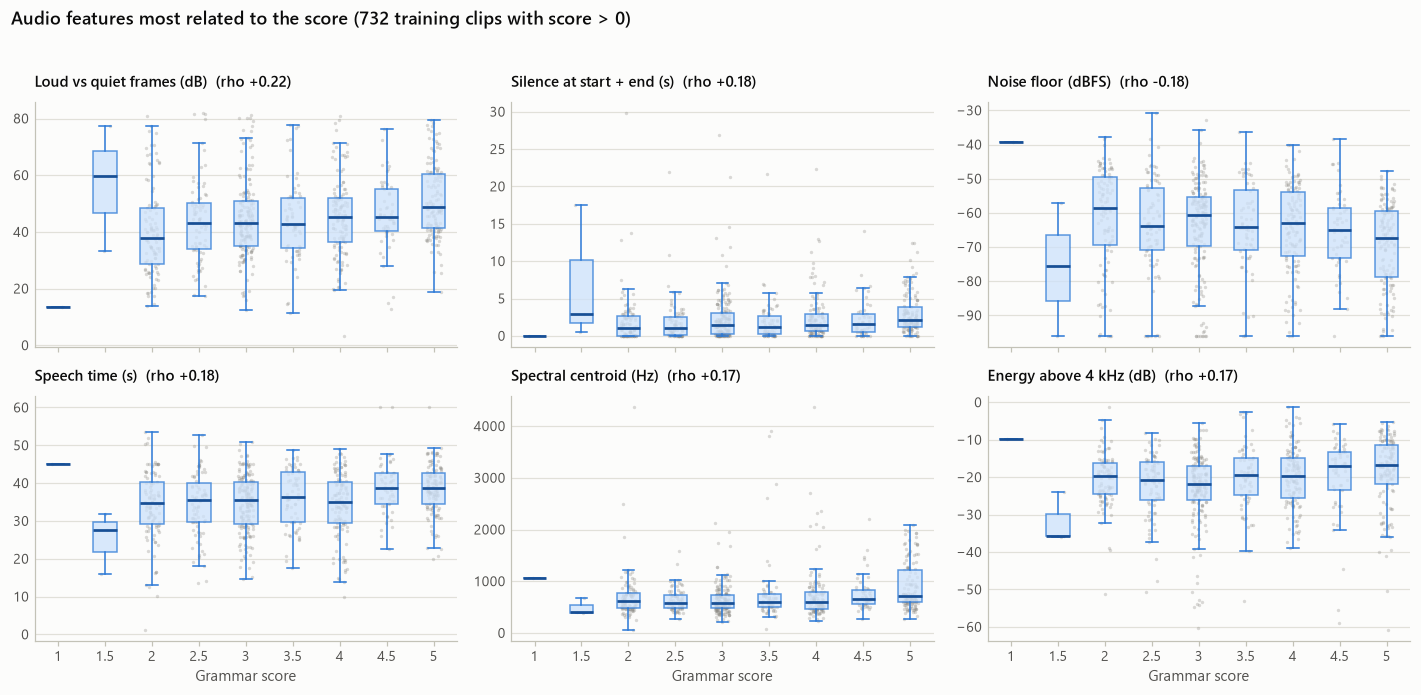

Clips per score: {'1': 1, '1.5': 3, '2': 102, '2.5': 79, '3': 174, '3.5': 64, '4': 124, '4.5': 52, '5': 133}


In [19]:
# The six features most related to real scores. Every clip is drawn, so tiny groups (scores 1 and 1.5) stay visible.
top = corr.reindex(corr["rho (score > 0)"].abs().sort_values(ascending=False).index).head(6)
scores = sorted(scored["label"].unique())
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)
for ax, (_, r) in zip(axes.ravel(), top.iterrows()):
    groups = [scored.loc[scored["label"] == s, r["col"]].dropna().to_numpy() for s in scores]
    for i, g in enumerate(groups):
        ax.scatter(i + rng.uniform(-0.16, 0.16, len(g)), g, s=5, color=MUTED, alpha=0.3, linewidth=0, zorder=1)
    ax.boxplot(groups, positions=range(len(scores)), widths=0.5, showfliers=False, patch_artist=True, zorder=2,
               boxprops=dict(facecolor=BLUE_WASH, edgecolor=BLUE, linewidth=1, alpha=0.75),
               medianprops=dict(color=BLUE_DARK, linewidth=1.8), whiskerprops=dict(color=BLUE, linewidth=1),
               capprops=dict(color=BLUE, linewidth=1))
    ax.set_xticks(range(len(scores)), [f"{s:g}" for s in scores])
    ax.set_title(f"{r['feature']}  (rho {r['rho (score > 0)']:+.2f})", fontsize=10)
for ax in axes[-1]: ax.set_xlabel("Grammar score")
fig.suptitle(f"Audio features most related to the score ({len(scored)} training clips with score > 0)", x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save(fig, "06_top_features_by_score")
print("Clips per score:", {f"{k:g}": int(v) for k, v in scored["label"].value_counts().sort_index().items()})

In [20]:
# Pause features by clip length, with and without the clips where the energy detector found no silence at all.
PAUSE_FEATS = ["pauses_per_min", "mean_pause_s", "max_pause_s", "long_pauses", "speech_ratio"]
c45, c60 = scored[scored["length_group"] == "~45 s"], scored[scored["length_group"] == "~60 s"]
pause_check = pd.DataFrame({
    f"60-s clips (n={len(c60)})": [rho(c60, c) for c in PAUSE_FEATS],
    f"60-s, detector worked (n={int((~c60['no_silence_found']).sum())})": [rho(c60[~c60["no_silence_found"]], c) for c in PAUSE_FEATS],
    f"45-s clips (n={len(c45)})": [rho(c45, c) for c in PAUSE_FEATS],
    f"45-s, detector worked (n={int((~c45['no_silence_found']).sum())})": [rho(c45[~c45["no_silence_found"]], c) for c in PAUSE_FEATS],
}, index=[FEATURES[c] for c in PAUSE_FEATS])
display(pause_check.style.format("{:+.2f}"))

failed45 = c45["no_silence_found"]
print(f"45-s clips where the detector found no silence: {int(failed45.sum())} of {len(c45)} ({failed45.mean():.0%}) | "
      f"their mean score {c45.loc[failed45, 'label'].mean():.2f} vs {c45.loc[~failed45, 'label'].mean():.2f} for the rest")

,60-s clips (n=527),"60-s, detector worked (n=524)",45-s clips (n=149),"45-s, detector worked (n=122)"
Pauses per minute,-0.17,-0.17,+0.12,+0.04
Mean pause length (s),-0.19,-0.19,+0.15,+0.07
Longest pause (s),-0.26,-0.25,+0.12,+0.03
Pauses >= 1 s,-0.22,-0.21,+0.16,+0.12
Share of clip detected as speech,+0.22,+0.21,-0.12,-0.04


45-s clips where the detector found no silence: 27 of 149 (18%) | their mean score 2.76 vs 3.13 for the rest


**What this shows**

- **Including the score-0 clips changes the picture completely** (dark vs light dots). Number of pauses, mean speech-run length and edge silence all move by 0.1 or more once those 37 clips are removed. Correlations computed on all clips mostly measure "is this a noise-bed clip".
- **On real scores, audio alone is weak.** The strongest feature reaches rho = +0.22 (gap between loud and quiet frames). Cleaner recordings, more speech time and more high-frequency content go with slightly higher scores.
- **Pause features look useless when pooled (|rho| ≤ 0.10), but that hides two different situations** (last table):
  - In **60-second clips**, more and longer pauses go with lower scores (longest pause −0.26, pauses ≥ 1 s −0.22, speech share +0.22). That is the fluency signal one would expect, and it does not depend on the clips where the detector failed.
  - In **45-second clips** the sign is reversed (+0.12 to +0.16). That comes from the 27 clips (18 %) where the energy detector found no silence at all: they are recorded as "zero pauses" and they score lower (2.76 vs 3.13). Leave them out and the pause features in this group are close to flat.
- So the fluency signal is visible in the 60-second clips and not in the 45-second ones, which are most of the test set. Whether it is really absent there, or just not measurable with an energy threshold on quieter, noisier recordings, can only be settled with word timings from Whisper.
- **Conclusion:** the transcript has to carry this task. Keep a few audio-quality features as controls, not as the core of the model.

## 8. Look and listen

One typical clip per score level (the clip whose detected speech share is closest to that score's median). Waveform on the left, mel spectrogram on the right. The audio players below hold a 12-second excerpt of each, starting where sound begins.

**Listen to the score-0 clip first.** Its waveform is a solid band and its spectrogram is filled at every frequency: that is the noise bed from section 5, with speech only faintly visible underneath.

**What each code cell does and why**

- **Cell 1 (pictures):** picks one typical clip per score and draws its waveform and spectrogram. The numbers describe the audio; this shows it.
- **Cell 2 (players):** lets you listen. It is the only way to confirm by ear what the measurements suggest.

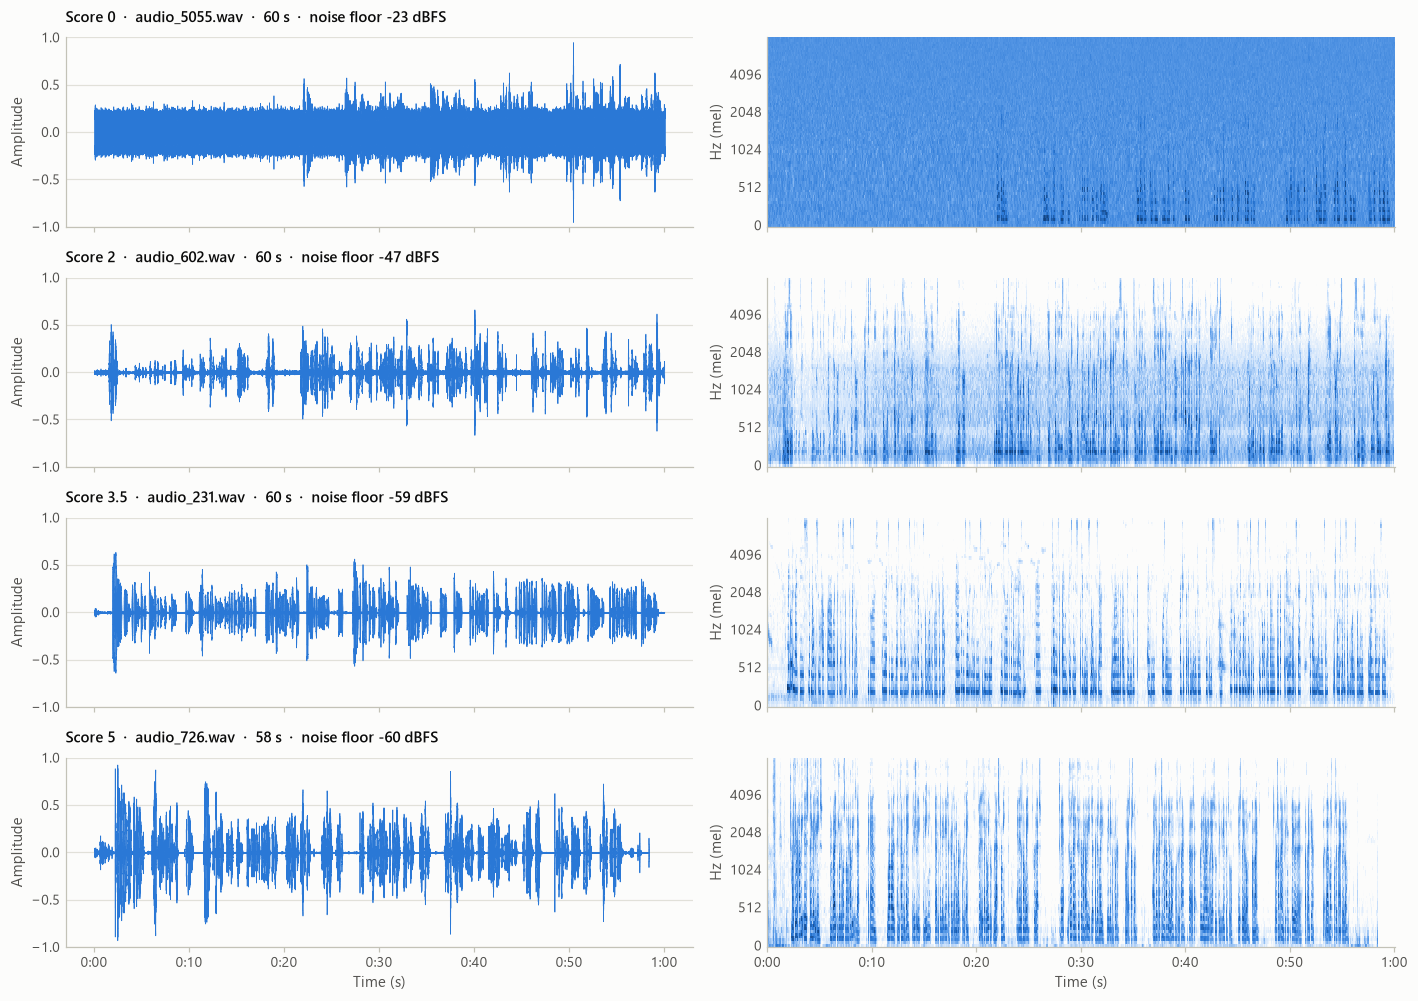

In [21]:
SHOW_SCORES = [0.0, 2.0, 3.5, 5.0]

def typical_clip(score):
    g = train[train["label"] == score]
    return g.loc[(g["speech_ratio"] - g["speech_ratio"].median()).abs().idxmin()]

examples = [typical_clip(s) for s in SHOW_SCORES]
fig, axes = plt.subplots(len(examples), 2, figsize=(13, 2.3 * len(examples)), sharex="col")
for (ax_w, ax_s), row in zip(axes, examples):
    yy, sr = librosa.load(row["path"], sr=None)
    librosa.display.waveshow(yy, sr=sr, ax=ax_w, color=BLUE, linewidth=0.5)
    ax_w.set_ylim(-1, 1); ax_w.set_ylabel("Amplitude"); ax_w.set_xlabel("")
    ax_w.set_title(f"Score {row['label']:g}  ·  {row['filename']}  ·  {row['duration']:.0f} s  ·  noise floor {row['noise_floor_db']:.0f} dBFS", fontsize=10)
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=yy, sr=sr, n_fft=FRAME, hop_length=HOP, n_mels=80), ref=np.max)
    librosa.display.specshow(mel, sr=sr, hop_length=HOP, x_axis="time", y_axis="mel", ax=ax_s, cmap=SEQ, vmin=-70, vmax=0)
    ax_s.grid(False); ax_s.set_ylabel("Hz (mel)"); ax_s.set_xlabel("")
axes[-1, 0].set_xlabel("Time (s)"); axes[-1, 1].set_xlabel("Time (s)")
fig.tight_layout()
save(fig, "07_example_clips")

In [22]:
for row in examples:
    yy, sr = librosa.load(row["path"], sr=None)
    start = int(row["lead_silence_s"] * sr)
    print(f"Score {row['label']:g}  |  {row['filename']}")
    display(Audio(yy[start:start + 12 * sr], rate=sr))

Score 0  |  audio_5055.wav


Score 2  |  audio_602.wav


Score 3.5  |  audio_231.wav


Score 5  |  audio_726.wav


## 9. Clips that need special handling

Simple rule-based flags. A flag is not a reason to drop a clip (test clips cannot be dropped at all); it marks clips to check after transcription, and shows whether poor recordings are scored differently. Mean scores are computed on clips with a score above 0.

**What the code cell does and why:** it applies the rules, counts flagged clips in train and test, compares their mean score with the rest, and saves the list to `flagged_clips.csv` so later stages can look these clips up.

In [23]:
ordinary = ~feats["noise_bed"]
FLAGS = {
    "noise bed (score-0 signature)":          feats["noise_bed"],
    "no silence found by energy detector":    feats["no_silence_found"] & ordinary,
    "high noise floor (> -40 dBFS)":          (feats["noise_floor_db"] > -40) & ordinary,
    "very quiet (RMS < -40 dBFS)":            feats["rms_dbfs"] < -40,
    "short (< 20 s)":                         feats["duration"] < 20,
    "mostly silent (speech < 30 %)":          feats["speech_ratio"] < 0.30,
    "long edge silence (> 5 s)":              feats["edge_silence_s"] > 5,
    "one pause longer than 10 s":             feats["max_pause_s"] > 10,
    "digital silence in >= 10 % of frames":   feats["noise_floor_db"] <= -96,
}
flag_df = pd.DataFrame(FLAGS)
is_train = feats["split"] == "train"
flag_table = pd.DataFrame([{
    "flag": name, "train clips": int(m[is_train].sum()), "train %": m[is_train].mean() * 100,
    "test clips": int(m[~is_train].sum()), "test %": m[~is_train].mean() * 100,
    "mean score if flagged": feats.loc[is_train & m, "label"].mean(),
    "mean score, other clips": feats.loc[is_train & ordinary & ~m, "label"].mean(),
} for name, m in flag_df.items()])
display(flag_table.style.format({"train %": "{:.1f}", "test %": "{:.1f}", "mean score if flagged": "{:.2f}", "mean score, other clips": "{:.2f}"}, na_rep="-"))

feats["n_flags"] = flag_df.sum(axis=1)
feats["flags"] = flag_df.apply(lambda r: "; ".join(k for k, v in r.items() if v), axis=1)
flagged = feats[feats["n_flags"] > 0].sort_values(["split", "n_flags"], ascending=[False, False])
flagged[["split", "filename", "label", "duration", "length_group", "rms_dbfs", "noise_floor_db", "speech_ratio", "max_pause_s", "flags"]].to_csv(EDA_DIR / "flagged_clips.csv", index=False)
print(f"Clips with at least one flag -> train: {int((feats['n_flags'] > 0)[is_train].sum())} / {int(is_train.sum())} | "
      f"test: {int((feats['n_flags'] > 0)[~is_train].sum())} / {int((~is_train).sum())}   (saved to flagged_clips.csv)")

print("\nShortest test clips:")
display(test.nsmallest(5, "duration")[["filename", "duration", "speech_s", "rms_dbfs", "noise_floor_db"]])

,flag,train clips,train %,test clips,test %,mean score if flagged,"mean score, other clips"
0,noise bed (score-0 signature),37,4.8,0,0.0,0.00,3.48
1,no silence found by energy detector,33,4.3,28,13.0,2.95,3.51
2,high noise floor (> -40 dBFS),10,1.3,10,4.6,2.70,3.49
3,very quiet (RMS < -40 dBFS),18,2.3,19,8.8,2.86,3.50
4,short (< 20 s),0,0.0,2,0.9,-,3.48
5,mostly silent (speech < 30 %),12,1.6,1,0.5,2.50,3.50
6,long edge silence (> 5 s),90,11.7,13,6.0,3.79,3.44
7,one pause longer than 10 s,4,0.5,2,0.9,2.38,3.49
8,digital silence in >= 10 % of frames,26,3.4,8,3.7,3.00,3.50


Clips with at least one flag -> train: 193 / 769 | test: 67 / 216   (saved to flagged_clips.csv)

Shortest test clips:


,filename,duration,speech_s,rms_dbfs,noise_floor_db
865,audio_107.wav,6.480,3.952,-35.957,-74.862
782,audio_28.wav,18.560,12.896,-30.232,-77.116
966,audio_48.wav,28.267,19.136,-23.294,-68.550
961,audio_29.wav,30.016,13.904,-22.756,-70.064
960,audio_50.wav,32.960,23.152,-22.615,-70.313


## 10. Findings and what they change

| # | Finding | Evidence | What to do |
|---|---|---|---|
| 1 | **Score 0 is a batch of noise-covered recordings, present only in train** | 37 of 37 match a two-threshold noise signature, 0 of 216 test clips do; own filename block | Train the grammar model on the 732 clips with score > 0. Report CV on those clips. Keep the two-threshold rule as a guard that outputs 0 if a clip ever matches. |
| 2 | **Test is mostly 45-s clips, train mostly 60-s** | 65 % vs 20 %; inside the 45-s group train and test are indistinguishable (AUC 0.48) | Stratify folds by length group and score. Report CV for the 45-s group on its own. |
| 3 | **45-s clips score lower and are quieter** | mean 3.06 vs 3.58; about 6 dB quieter | Expect a lower mean score on test (about 3.25 vs 3.48). Use per-minute rates, not raw counts. |
| 4 | **The SNR estimate has a blind spot** | 96 clips have no measurable SNR and would be logged as 40 dB; only 1 clip falls below the 15 dB threshold | Gate noise reduction on noise floor / loud-vs-quiet gap instead of `estimate_snr`. |
| 5 | **Energy-based pause features fail on noisy clips** | 9 % of train and 13 % of test show "0 pauses"; the pause-score relationship flips sign in 45-s clips | Take pauses and speech rate from Whisper word timestamps. |
| 6 | **Fluency carries signal where it can be measured** | In 60-s clips: longest pause rho −0.26, speech share +0.22 | Worth building properly from word timings. |
| 7 | **Audio statistics alone are weak** | best rho +0.22 on real scores | The transcript has to carry the model. |
| 8 | **Format is uniform and clean** | 16 kHz mono PCM-16, 0 unreadable, no clipping, no DC offset | Resampling and DC removal change nothing; keep as guards. |
| 9 | **Loudness varies by about 20 dB; test is quieter** | 34 % of test below −32 dBFS vs 10 % of train | Keep loudness normalisation. |
| 10 | **`sample_submission.csv` does not match `test.csv`** | 204 vs 216 rows, 25 shared filenames | Build the submission from `test.csv`. Confirm which file list is actually scored. |
| 11 | **Filenames repeat across train and test** | 212 shared names, different audio | Key every table on (`split`, `filename`). |
| 12 | **Labels: effective range 2–5, 74 % whole numbers** | 4 clips between 0.5 and 1.5 | Regression, clipped to 0–5. Expect roughly half a point of label noise. |
| 13 | **Two very short test clips** | 6.5 s and 18.6 s; shortest train clip is 20 s | Read their transcripts by hand before trusting the prediction. |

**Not covered here (needs the next stage)**

- What is said in each clip: transcripts, word counts, grammar errors, and whether the batches correspond to different speaking prompts.
- Whether the same speaker appears in several clips. If so, folds should be grouped by speaker. That cannot be seen from the audio statistics used here.
- What is audible in the score-0 clips. The player in section 8 lets you check by ear, and the ASR stage will show whether Whisper recovers any words from them.

**The code cell below** saves the key numbers of Part 1 to `eda_summary.json`, so later steps read them instead of computing them again.

In [24]:
# Machine-readable summary, so the preprocessing and modelling notebooks can read these numbers instead of re-deriving them.
top5 = corr.reindex(corr["rho (score > 0)"].abs().sort_values(ascending=False).index).head(5)
summary = {
    "clips": {"train": int(len(train)), "test": int(len(test))},
    "hours": {"train": round(float(train["duration"].sum() / 3600), 2), "test": round(float(test["duration"].sum() / 3600), 2)},
    "format": {"sample_rates": sorted(int(v) for v in feats["sr"].unique()), "channels": sorted(int(v) for v in feats["channels"].unique()),
               "unreadable_files": int((~feats["readable"]).sum()), "byte_identical_audio": int(len(dup))},
    "label": {**{k: round(v, 4) if isinstance(v, float) else v for k, v in label_stats.items()},
              "std_score_above_0": round(float(scored["label"].std(ddof=0)), 4)},
    "noise_bed": {"rule": f"noise_floor_db > {NOISE_FLOOR_MIN} and hf_ratio_db > {HF_RATIO_MIN}",
                  "train_clips": int(train["noise_bed"].sum()), "of_which_score_0": int((train["noise_bed"] & (train["label"] == 0)).sum()),
                  "test_clips": int(test["noise_bed"].sum()), "noise_spotter_pearson": round(float(spotter_r), 3)},
    "length_groups": {"share_45s": {"train": round(float((scored["length_group"] == "~45 s").mean()), 3), "test": round(float((real_test["length_group"] == "~45 s").mean()), 3)},
                      "mean_score": {g: round(float(v), 3) for g, v in by_len["mean_score"].items()},
                      "train_mean_score": round(float(scored["label"].mean()), 3), "train_mean_reweighted_to_test_mix": round(reweighted, 3)},
    "adversarial_auc": {f"{r['clips compared']} | {r['features given to the classifier']}": round(float(r["train-vs-test AUC"]), 3) for _, r in adv.iterrows()},
    "snr": {"clips_below_15_db": int((feats["snr_db"] < SNR_THRESHOLD).sum()), "clips_not_measurable": int(feats["snr_db"].isna().sum())},
    "pct_no_silence_found": {"train": round(float(train["no_silence_found"].mean() * 100), 1), "test": round(float(test["no_silence_found"].mean() * 100), 1)},
    "strongest_correlations_score_above_0": {r["feature"]: round(float(r["rho (score > 0)"]), 3) for _, r in top5.iterrows()},
    "sample_submission": {"rows": int(len(sub_df)), "names_in_test_csv": int(len(sub_names & te_names))},
}
(EDA_DIR / "eda_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print("\nSaved in", EDA_DIR, "->", sorted(p.name for p in EDA_DIR.iterdir()))

{
  "clips": {
    "train": 769,
    "test": 216
  },
  "hours": {
    "train": 11.92,
    "test": 2.93
  },
  "format": {
    "sample_rates": [
      16000
    ],
    "channels": [
      1
    ],
    "unreadable_files": 0,
    "byte_identical_audio": 0
  },
  "label": {
    "n": 769,
    "mean": 3.3134,
    "median": 3.0,
    "std": 1.2382,
    "share_whole_number": 0.7425,
    "n_score_0": 37,
    "n_between_0.5_and_1.5": 4,
    "baseline_rmse_predict_mean": 1.2382,
    "baseline_mae_predict_median": 0.987,
    "std_score_above_0": 1.0137
  },
  "noise_bed": {
    "rule": "noise_floor_db > -30.0 and hf_ratio_db > -8.0",
    "train_clips": 37,
    "of_which_score_0": 37,
    "test_clips": 0,
    "noise_spotter_pearson": 0.602
  },
  "length_groups": {
    "share_45s": {
      "train": 0.204,
      "test": 0.653
    },
    "mean_score": {
      "~45 s": 3.06,
      "~60 s": 3.584,
      "other": 3.625
    },
    "train_mean_score": 3.481,
    "train_mean_reweighted_to_test_mix": 3.245


# Part 2 - From audio to text

Part 1 looked at the data. Part 2 turns each recording into what a grammar model can actually read: a faithful transcript, with a time stamp on every word.

| Section | What it does | Why we need it |
|---|---|---|
| 11 | Cleans the audio | Whisper (and later audio models) should hear every speaker under the same conditions |
| 12 | Transcribes with Whisper | Grammar is judged from the words, so we need the words |
| 13 | Checks the transcripts | Every later feature is built on this text, so problems must be caught here |

Both slow steps save their results in `shl-hiring-assessment-2026/working/`, so they run once. If a run is interrupted, running the cell again continues where it stopped.

## 11. Clean the audio

**Why this step:** Whisper should hear every speaker under the same conditions, and nothing in the cleaning may change *what was said*. Part 1 decides what goes in and what stays out:

| Operation | Used? | Reason (from Part 1) |
|---|---|---|
| Resample to 16 kHz mono | guard only | Every file already is 16 kHz mono (section 3), so this changes nothing here |
| Remove DC offset | yes | Harmless; the largest offset is 0.002 (section 4) |
| Trim silence at the start and end | yes | 12 % of train clips carry more than 5 s of dead air (section 4). Pauses *inside* the speech are never touched, because they are a fluency signal |
| Loudness normalisation to -23 LUFS | yes | Loudness spreads over about 20 dB and test is quieter than train (section 4) |
| Noise reduction | **no** | The old SNR rule would have fired on 1 clip of 985 (section 4). Noise reduction also alters the speech itself. This is a choice, not a measured result: it can be tested later by transcribing the noisy clips both ways |

**What each code cell does and why**

- **Cell 1 (`clean_clip`):** applies those operations to one file and writes a 16-bit WAV into `working/clean_audio/<split>/`. It returns how much was trimmed at the start (`trim_start_s`), so that word times can be mapped back to the original recording, and the loudness before and after.
- **Cell 2 (run and check):** cleans all 985 clips in parallel, saves an index table, and prints a before/after summary to confirm the step did what it should.

In [25]:
import re, textwrap
import pyloudnorm as pyln

CLEAN_DIR = WORK_DIR / "clean_audio"
TARGET_SR, TARGET_LUFS, EDGE_PAD_S = 16000, -23.0, 0.25

def clean_clip(path, out_path):
    y, sr = sf.read(path, dtype="float32", always_2d=True)
    y = y.mean(axis=1)
    if sr != TARGET_SR:                                    # guard: every file in this dataset is already 16 kHz
        y, sr = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR), TARGET_SR
    y = y - y.mean()                                       # DC offset

    # Trim dead air at the two ends only, keeping a short pad so the first and last word are not cut
    n_before = len(y)
    _, (start, end) = librosa.effects.trim(y, top_db=TRIM_DB)
    pad = int(EDGE_PAD_S * sr)
    a, b = max(0, start - pad), min(n_before, end + pad)
    y = y[a:b]

    # Same perceived loudness for every clip (EBU R128), then keep peaks below full scale
    meter = pyln.Meter(sr)
    loud_before = meter.integrated_loudness(y) if len(y) > sr else -np.inf
    if np.isfinite(loud_before):
        y = y * 10 ** ((TARGET_LUFS - loud_before) / 20)
    peak = float(np.abs(y).max()) if len(y) else 0.0
    if peak > 0.99:
        y = y / peak * 0.99
    loud_after = meter.integrated_loudness(y) if len(y) > sr else -np.inf

    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    sf.write(out_path, y, sr, subtype="PCM_16")
    return {"clean_path": str(out_path), "trim_start_s": a / sr, "trim_end_s": (n_before - b) / sr, "clean_duration": len(y) / sr,
            "loudness_before_lufs": float(loud_before), "loudness_after_lufs": float(loud_after), "peak_limited": bool(peak > 0.99)}

In [26]:
CLEAN_CSV = WORK_DIR / "clean_audio_index.csv"

clean = pd.read_csv(CLEAN_CSV) if CLEAN_CSV.exists() else None
if clean is not None and len(clean) == len(feats) and all(os.path.exists(p) for p in clean["clean_path"]):
    print(f"Loaded index of {len(clean)} cleaned clips from {CLEAN_CSV.name}")
else:
    t0 = time.time()
    jobs = [(src, CLEAN_DIR / split / name) for src, split, name in zip(feats["path"], feats["split"], feats["filename"])]
    rows = Parallel(n_jobs=min(8, os.cpu_count()))(delayed(clean_clip)(src, dst) for src, dst in jobs)
    clean = pd.concat([feats[["split", "filename"]].reset_index(drop=True), pd.DataFrame(rows)], axis=1)
    clean.to_csv(CLEAN_CSV, index=False)
    print(f"Cleaned {len(clean)} clips in {time.time() - t0:.0f} s -> {CLEAN_DIR}")

# Did the step do what it should? Compare before and after.
clean["trimmed_s"] = clean["trim_start_s"] + clean["trim_end_s"]
spread = lambda s: s[np.isfinite(s)].quantile(0.95) - s[np.isfinite(s)].quantile(0.05)
display(clean.groupby("split", sort=False).agg(
    clips=("filename", "size"),
    hours_after_trimming=("clean_duration", lambda s: s.sum() / 3600),
    minutes_of_silence_removed=("trimmed_s", lambda s: s.sum() / 60),
    median_trimmed_s=("trimmed_s", "median"),
    loudness_spread_before_db=("loudness_before_lufs", spread),
    loudness_spread_after_db=("loudness_after_lufs", spread),
    pct_peak_limited=("peak_limited", lambda s: s.mean() * 100),
).T.style.format("{:.3g}"))

Loaded index of 985 cleaned clips from clean_audio_index.csv


split,train,test
clips,769,216
hours_after_trimming,11.5,2.84
minutes_of_silence_removed,25.3,4.9
median_trimmed_s,1.06,0.722
loudness_spread_before_db,17.9,22.1
loudness_spread_after_db,1.84,5.87
pct_peak_limited,17,27.3


**What this shows**

- All 985 clips were cleaned in under half a minute. Trimming removed about 30 minutes of silence in total, usually around 1 s per clip. 14.3 hours of audio remain.
- **Loudness is now much more even:** the spread between quiet and loud clips fell from 17.9 dB to 1.8 dB in train and from 22.1 dB to 5.9 dB in test.
- **Limitation:** 17 % of train clips and 27 % of test clips were "peak limited". One loud peak (a click, a tap on the microphone) reaches full scale before the clip reaches the target loudness, so those clips stay quieter than the rest. That is why the test spread is still 5.9 dB. A limiter that squashes only the peaks would remove this; section 13 shows it is not urgent, because Whisper's confidence does not depend on how loud the recording was.

## 12. Transcribe with Whisper

**Why this step:** the grammar score is about the words, and Part 1 showed that audio statistics alone barely relate to it (best correlation +0.22). The transcript is the main input of the model.

**The risk:** Whisper can tidy up speech, and it can also invent text. Either would damage a grammar score, so the settings below were chosen by testing on 24 training clips (12 of each length) before the full run:

| Setting | Why |
|---|---|
| Model `medium.en` | Tested against the faster `large-v3-turbo`. Turbo left the second half of 10-15 of the 24 clips without sentence punctuation; `medium.en` did so for 2. Grammar tools need sentence boundaries, so consistent text matters more than speed |
| `language="en"` | No language detection, which can go wrong on accented or noisy speech |
| `temperature=0`, `beam_size=5` | Deterministic decoding: the same audio gives the same text on every run |
| `condition_on_previous_text=True` | Whisper reads a clip in 30-second windows. Carrying the previous text into the next window keeps punctuation and capital letters consistent across the clip (2 instead of 5 of 24 clips with an unpunctuated second half) |
| Retry guard (`LOOP_RATIO`) | Carrying text forward can, rarely, start a runaway repetition. If the text of a clip is very repetitive (compression ratio above 2.4), the clip is decoded again with each window on its own |
| No "verbatim" prompt | The original plan gave Whisper an example of hesitant speech so that it would keep fillers. In the test this made Whisper invent text on a clip: one model wrote "uh, uh, uh, ..." over and over, the other repeated the prompt itself and lost the speaker's opening words. Applying the prompt to every window caused runaway repetition on 2 of 6 clips. The library also applies such a prompt only to the first 30 seconds of a 45-60 s clip, so the two halves would be treated differently |
| `vad_filter=False` | Silence inside the speech stays in place, so word times stay true to the recording |
| `word_timestamps=True` | A start and end time for every word. Part 1 showed that energy-based pause detection fails on 9-13 % of clips; word times replace it |

**What Whisper does not give us:** without a prompt it drops most fillers ("um", "uh") and probably many repeated words. The transcript is faithful about *which words and which grammar* were used (errors such as "there was many people" are kept), not about every hesitation. Fluency is therefore measured from word times, not from counting "um".

**What each code cell does and why**

- **Cell 1 (model setup):** chooses the Whisper model for this machine and makes the GPU libraries visible to Windows. On a 4 GB graphics card the model uses about 1 GB.
- **Cell 2 (`transcribe`):** runs one clip and returns the text, Whisper's own confidence numbers, and the list of words with their times.
- **Cell 3 (run all clips):** loops over every clip (about an hour on this laptop). Each result is written to disk immediately, so an interrupted run continues instead of starting again.

In [27]:
import sysconfig

# The GPU libraries installed with pip are not on the Windows search path by default: add them before Whisper loads.
if os.name == "nt":
    for sub in ("cublas", "cudnn", "cuda_nvrtc"):
        dll_dir = Path(sysconfig.get_paths()["purelib"]) / "nvidia" / sub / "bin"
        if dll_dir.is_dir():
            os.add_dll_directory(str(dll_dir))
            os.environ["PATH"] = str(dll_dir) + os.pathsep + os.environ["PATH"]

import ctranslate2
from faster_whisper import WhisperModel

DEVICE = "cuda" if ctranslate2.get_cuda_device_count() > 0 else "cpu"
ASR_MODEL = "medium.en" if DEVICE == "cuda" else "small.en"            # the CPU fallback is slower and less accurate
COMPUTE_TYPE = "int8_float16" if DEVICE == "cuda" else "int8"          # about 1 GB of GPU memory, safe on a 4 GB card
LOOP_RATIO = 2.4                                                       # compression ratio above this means repeated text

ASR_DIR = WORK_DIR / "asr"
ASR_DIR.mkdir(parents=True, exist_ok=True)
ASR_JSONL = ASR_DIR / f"transcripts_{ASR_MODEL}.jsonl"
print(f"Whisper model: {ASR_MODEL} on {DEVICE} ({COMPUTE_TYPE}) | results file: {ASR_JSONL.name}")

Whisper model: medium.en on cuda (int8_float16) | results file: transcripts_medium.en.jsonl


In [28]:
_asr = None

def get_asr():
    # Load the model only when there is something left to transcribe, so re-running the notebook needs no GPU.
    global _asr
    if _asr is None:
        _asr = WhisperModel(ASR_MODEL, device=DEVICE, compute_type=COMPUTE_TYPE)
    return _asr

def run_whisper(audio, carry_context):
    segments, _ = get_asr().transcribe(audio, language="en", beam_size=5, temperature=0.0,
                                       condition_on_previous_text=carry_context, vad_filter=False, word_timestamps=True)
    return list(segments)                                  # the model only runs when this generator is consumed

def transcribe(path):
    audio, _ = sf.read(path, dtype="float32")              # cleaned clips are already 16 kHz mono, so no decoding step is needed
    segments = run_whisper(audio, carry_context=True)
    retried = max((s.compression_ratio for s in segments), default=0) > LOOP_RATIO
    if retried:                                            # runaway repetition: decode again with each window on its own
        segments = run_whisper(audio, carry_context=False)
    words = [w for s in segments for w in (s.words or [])]
    return {
        "transcript": " ".join(s.text.strip() for s in segments).strip(),
        "asr_avg_logprob": float(np.mean([s.avg_logprob for s in segments])) if segments else None,
        "asr_no_speech": float(np.mean([s.no_speech_prob for s in segments])) if segments else None,
        "asr_compression": float(max(s.compression_ratio for s in segments)) if segments else None,
        "asr_retried": bool(retried),
        "words": [[w.word.strip(), round(float(w.start), 2), round(float(w.end), 2), round(float(w.probability), 3)] for w in words],
    }

In [29]:
# Results already on disk (a half-written last line from an interrupted run is skipped and redone)
done = {}
if ASR_JSONL.exists():
    for line in ASR_JSONL.read_text(encoding="utf-8").splitlines():
        try:
            rec = json.loads(line)
            done[(rec["split"], rec["filename"])] = rec
        except (json.JSONDecodeError, KeyError):
            pass

todo = [r for r in clean.itertuples(index=False) if (r.split, r.filename) not in done]
print(f"Already transcribed: {len(done)} clips | still to do: {len(todo)}")

if todo:
    t0, audio_s = time.time(), 0.0
    with open(ASR_JSONL, "a", encoding="utf-8") as fh:
        for i, r in enumerate(todo, 1):
            rec = {"split": r.split, "filename": r.filename, **transcribe(r.clean_path)}
            fh.write(json.dumps(rec, ensure_ascii=False) + "\n")
            fh.flush()
            done[(r.split, r.filename)] = rec
            audio_s += r.clean_duration
            if i % 100 == 0 or i == len(todo):
                elapsed = time.time() - t0
                print(f"  {i}/{len(todo)} clips | {elapsed / 60:.1f} min | {audio_s / elapsed:.1f}x real time")
print(f"Transcripts available for {len(done)} of {len(clean)} clips")

Already transcribed: 985 clips | still to do: 0
Transcripts available for 985 of 985 clips


**What this shows**

- All 985 clips were transcribed in 77 minutes on the laptop GPU, at about 11 times real time, with no failures.
- The text and the word times are saved in `working/asr/transcripts_medium.en.jsonl` (one line per clip). Running this notebook again loads them and does not transcribe anything.

## 13. Check the transcripts

**Why this step:** every later feature is built on these transcripts, so a problem here (empty text, runaway repetition, invented words) would silently damage the model. This section also answers two questions Part 1 left open:

1. What does Whisper hear in the 37 noise-covered clips?
2. Part 1 could not measure fluency on the 45-second clips with an energy threshold. Do word times fix that?

**What each code cell does and why**

- **Cell 1 (one row per clip):** builds a table with the text, the word count, the speaking rate, and pauses measured from the gaps between words.
- **Cell 2 (sanity checks):** counts the failure cases, and compares the noise-covered clips with the rest.
- **Cell 3 (read some):** prints the transcripts of the four example clips from section 8, so the text can be read next to the audio.
- **Cell 4 (relation to the score):** relates the new measures to the grammar score, separately for 45-second and 60-second clips, and saves the table for the modelling step.
- **Cell 5 (two follow-up checks):** asks whether Whisper's confidence is only a measure of recording quality, and whether the gaps between word times are real pauses. Both answers decide which features are worth building.

In [30]:
FILLER_RE = re.compile(r"\b(um+|uh+|er+m?|ah+|hm+|mm+)\b", re.I)

def clip_measures(rec):
    # Everything here comes from Whisper's word list: [word, start, end, probability]
    w, text = rec["words"], rec["transcript"]
    tokens = re.findall(r"[a-z']+", text.lower())
    out = {"n_words": len(w), "n_fillers": len(FILLER_RE.findall(text)), "n_repeats": sum(a == b for a, b in zip(tokens, tokens[1:]))}
    if not w:
        return {**out, "wt_pauses": 0, "wt_long_pauses": 0, "wt_mean_pause_s": 0.0, "wt_max_pause_s": 0.0, "asr_word_conf": np.nan, "low_conf_share": np.nan}
    start, end, prob = (np.array([x[i] for x in w], dtype=float) for i in (1, 2, 3))
    gaps = start[1:] - end[:-1]
    pauses = gaps[gaps >= MIN_PAUSE]                       # same 0.3 s definition as Part 1
    return {**out, "wt_pauses": int(len(pauses)), "wt_long_pauses": int((pauses >= LONG_PAUSE).sum()),
            "wt_mean_pause_s": float(pauses.mean()) if len(pauses) else 0.0, "wt_max_pause_s": float(pauses.max()) if len(pauses) else 0.0,
            "asr_word_conf": float(prob.mean()), "low_conf_share": float((prob < 0.5).mean())}

tx = pd.DataFrame([{k: v for k, v in rec.items() if k != "words"} | clip_measures(rec) for rec in done.values()])
tx = tx.merge(clean[["split", "filename", "clean_duration", "trim_start_s"]], on=["split", "filename"])
tx = tx.merge(feats[["split", "filename", "label", "length_group", "noise_bed", "no_silence_found", "pauses_per_min", "max_pause_s"]], on=["split", "filename"])
minutes = tx["clean_duration"] / 60
tx["words_per_min"] = tx["n_words"] / minutes
tx["wt_pauses_per_min"] = tx["wt_pauses"] / minutes
tx["wt_long_pauses_per_min"] = tx["wt_long_pauses"] / minutes
tx["fillers_per_100w"] = tx["n_fillers"] / tx["n_words"].clip(lower=1) * 100
tx["repeats_per_100w"] = tx["n_repeats"] / tx["n_words"].clip(lower=1) * 100
print(f"{len(tx)} clips | {int(tx['n_words'].sum()):,} words in total")
display(tx[["split", "filename", "label", "n_words", "words_per_min", "wt_pauses_per_min", "asr_word_conf", "transcript"]].head())

985 clips | 97,179 words in total


,split,filename,label,n_words,words_per_min,wt_pauses_per_min,asr_word_conf,transcript
0,train,audio_192.wav,3.0,94,99.373,9.514,0.732,"Well, the playground is very, very beautiful a..."
1,train,audio_436.wav,3.0,105,106.757,6.100,0.818,"The scene of a school playground, our playgrou..."
2,train,audio_447.wav,3.5,149,149.573,6.023,0.881,My favorite place to visit is the beach. I lov...
3,train,audio_126.wav,2.0,96,127.830,1.332,0.821,and once upon a time we with 5 friends went on...
4,train,audio_61.wav,2.0,74,104.446,11.291,0.870,"Well, when I was a child, I remember I went to..."


In [31]:
tx_train = tx["split"] == "train"
CHECKS = {
    "clips transcribed":                                    pd.Series(True, index=tx.index),
    "empty transcript":                                     tx["n_words"] == 0,
    "fewer than 15 words":                                  tx["n_words"] < 15,
    "possible repetition loop (compression ratio > 2.4)":   tx["asr_compression"] > 2.4,
    "decoded twice by the retry guard":                     tx["asr_retried"],
    "at least one filler written (um, uh, hmm ...)":        tx["n_fillers"] > 0,
    "at least one repeated word written (I I, the the)":    tx["n_repeats"] > 0,
}
display(pd.DataFrame([{"check": k, "train": int(m[tx_train].sum()), "test": int(m[~tx_train].sum())} for k, m in CHECKS.items()]))

# What does Whisper make of the noise-covered clips?
group = np.where(tx["noise_bed"], "noise-bed clips (score 0)", np.where(tx_train, "other train clips", "test clips"))
display(tx.groupby(group).agg(clips=("filename", "size"), median_words=("n_words", "median"), median_words_per_min=("words_per_min", "median"),
                              median_word_confidence=("asr_word_conf", "median"), median_no_speech_prob=("asr_no_speech", "median")).style.format("{:.3g}"))

,check,train,test
0,clips transcribed,769,216
1,empty transcript,0,0
2,fewer than 15 words,0,1
3,possible repetition loop (compression ratio > ...,3,0
4,decoded twice by the retry guard,14,1
5,"at least one filler written (um, uh, hmm ...)",18,6
6,"at least one repeated word written (I I, the the)",122,27


,clips,median_words,median_words_per_min,median_word_confidence,median_no_speech_prob
noise-bed clips (score 0),37,101,106,0.64,0.655
other train clips,732,100,113,0.894,0.323
test clips,216,94,123,0.897,0.341


In [32]:
# The same four clips as in section 8, so the text can be read next to the audio.
for row in examples:
    rec = tx[tx_train & (tx["filename"] == row["filename"])].iloc[0]
    text = rec["transcript"][:600] + (" ..." if len(rec["transcript"]) > 600 else "")
    print(f"Score {row['label']:g} | {row['filename']} | {rec['n_words']} words | {rec['words_per_min']:.0f} words/min | word confidence {rec['asr_word_conf']:.2f}")
    print(textwrap.fill(text, width=140, initial_indent="   ", subsequent_indent="   ") or "   (no words)")
    print()

Score 0 | audio_5055.wav | 51 words | 51 words/min | word confidence 0.56
   When pedaling, the wind blows on my skin. Since then, I've tried to change my daily life. Every time I leave my home, I think, make
   myself forget, at least, whatever it is. Into an accident, but just flooding my heart. So, I have two teeth, and let them go home.

Score 2 | audio_602.wav | 112 words | 112 words/min | word confidence 0.83
   Market is a crowded place and here selling and buying takes place and there are a lot of the people where transactions will be held there
   like exchanging between the seller and buyer goods and their vegetable vendors and some other things are going on in the crowd like
   whatever we want we go to the market and buy the and it is like shouting there like selling their prices and increasing as compared to
   the others and like that there will be takes place and market is a good thing for everyone to take the things from there and it is a
   crowded place the scene is t

,all scored clips (n=732),60-s clips (n=527),45-s clips (n=149)
Words spoken,+0.38,+0.42,+0.13
Words per minute,+0.32,+0.44,+0.17
Pauses per minute (word times),+0.23,+0.24,+0.25
"Pauses per minute (energy, Part 1)",-0.05,-0.17,+0.12
Longest pause (word times),+0.05,-0.06,+0.14
"Longest pause (energy, Part 1)",-0.10,-0.26,+0.12
Pauses >= 1 s per minute (word times),+0.12,+0.04,+0.14
Mean pause length (word times),-0.02,-0.12,+0.06
Whisper word confidence,+0.62,+0.72,+0.52
Share of low-confidence words,-0.53,-0.63,-0.46


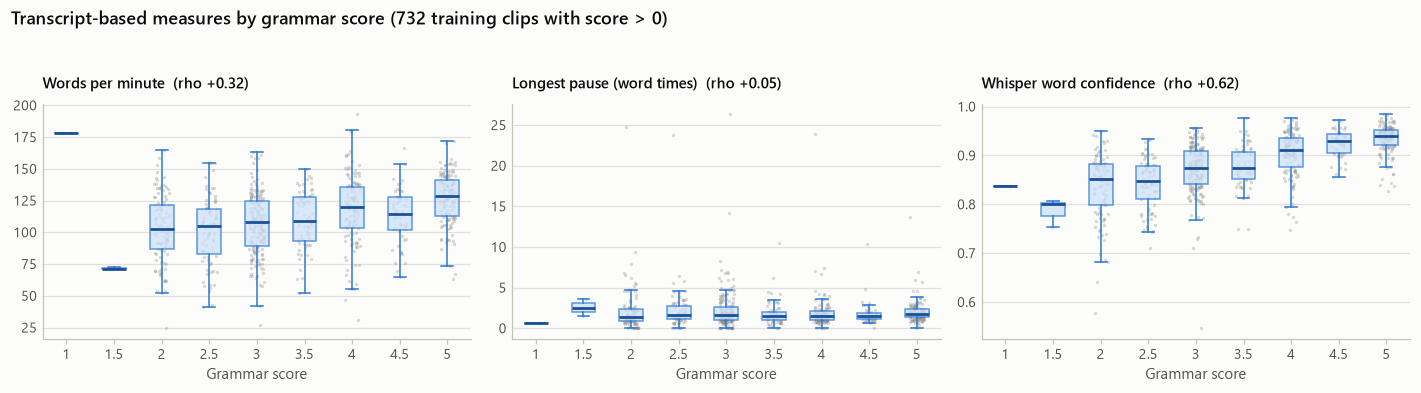

Saved transcripts.csv (985 rows). Word-level times stay in transcripts_medium.en.jsonl.


In [33]:
tx_scored = tx[tx_train & ~tx["noise_bed"]]
MEASURES = {
    "n_words": "Words spoken", "words_per_min": "Words per minute",
    "wt_pauses_per_min": "Pauses per minute (word times)", "pauses_per_min": "Pauses per minute (energy, Part 1)",
    "wt_max_pause_s": "Longest pause (word times)", "max_pause_s": "Longest pause (energy, Part 1)",
    "wt_long_pauses_per_min": "Pauses >= 1 s per minute (word times)", "wt_mean_pause_s": "Mean pause length (word times)",
    "asr_word_conf": "Whisper word confidence", "low_conf_share": "Share of low-confidence words",
    "fillers_per_100w": "Fillers per 100 words", "repeats_per_100w": "Repeated words per 100 words",
}
t60, t45 = tx_scored[tx_scored["length_group"] == "~60 s"], tx_scored[tx_scored["length_group"] == "~45 s"]
rho_tx = pd.DataFrame({
    f"all scored clips (n={len(tx_scored)})": [rho(tx_scored, c) for c in MEASURES],
    f"60-s clips (n={len(t60)})": [rho(t60, c) for c in MEASURES],
    f"45-s clips (n={len(t45)})": [rho(t45, c) for c in MEASURES],
}, index=list(MEASURES.values()))
display(rho_tx.style.format("{:+.2f}", na_rep="n/a"))

def box_by_score(ax, df, col, title):
    levels = sorted(df["label"].unique())
    groups = [df.loc[df["label"] == s, col].dropna().to_numpy() for s in levels]
    jitter = np.random.default_rng(SEED)
    for i, g in enumerate(groups):
        ax.scatter(i + jitter.uniform(-0.16, 0.16, len(g)), g, s=5, color=MUTED, alpha=0.3, linewidth=0, zorder=1)
    ax.boxplot(groups, positions=range(len(levels)), widths=0.5, showfliers=False, patch_artist=True, zorder=2,
               boxprops=dict(facecolor=BLUE_WASH, edgecolor=BLUE, linewidth=1, alpha=0.75),
               medianprops=dict(color=BLUE_DARK, linewidth=1.8), whiskerprops=dict(color=BLUE, linewidth=1),
               capprops=dict(color=BLUE, linewidth=1))
    ax.set_xticks(range(len(levels)), [f"{s:g}" for s in levels])
    ax.set_xlabel("Grammar score"); ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["words_per_min", "wt_max_pause_s", "asr_word_conf"]):
    box_by_score(ax, tx_scored, col, f"{MEASURES[col]}  (rho {rho(tx_scored, col):+.2f})")
fig.suptitle(f"Transcript-based measures by grammar score ({len(tx_scored)} training clips with score > 0)", x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
save(fig, "08_transcript_measures_by_score")

TX_CSV = ASR_DIR / "transcripts.csv"
tx.to_csv(TX_CSV, index=False)
print(f"Saved {TX_CSV.name} ({len(tx)} rows). Word-level times stay in {ASR_JSONL.name}.")

In [34]:
# 1) Is Whisper's confidence only a measure of recording quality? Compare it with the audio measures from Part 1.
q = tx_scored.merge(feats[["split", "filename", "rms_dbfs", "dyn_range_db", "noise_floor_db"]], on=["split", "filename"])
COMPARE = [("label", "grammar score"), ("words_per_min", "words per minute"), ("dyn_range_db", "loud vs quiet frames (dB)"),
           ("noise_floor_db", "noise floor (dBFS)"), ("rms_dbfs", "loudness before cleaning (dBFS)")]
conf_vs = pd.Series({name: stats.spearmanr(q["asr_word_conf"], q[col]).statistic for col, name in COMPARE}, name="rho with Whisper word confidence")
display(conf_vs.to_frame().style.format("{:+.2f}"))
display(tx_scored.groupby("label")["asr_word_conf"].agg(clips="size", median_word_confidence="median").T.style.format("{:.3g}"))

# 2) Are the gaps between Whisper's word times real pauses? Look at where they fall.
noise_keys = set(zip(tx.loc[tx["noise_bed"], "split"], tx.loc[tx["noise_bed"], "filename"]))
pairs = gaps = after_punct = 0
for rec in done.values():
    if (rec["split"], rec["filename"]) in noise_keys:
        continue
    for a, b in zip(rec["words"], rec["words"][1:]):
        pairs += 1
        if b[1] - a[2] >= MIN_PAUSE:
            gaps += 1
            after_punct += a[0].rstrip().endswith((".", "?", "!", ","))
print(f"{pairs:,} neighbouring word pairs | a gap of {MIN_PAUSE} s or more between them: {gaps / pairs:.1%} | of those gaps, {after_punct / gaps:.0%} come right after a comma or sentence mark")
print(f"Pauses per minute from word times vs from energy (Part 1): rho = {stats.spearmanr(tx_scored['wt_pauses_per_min'], tx_scored['pauses_per_min']).statistic:+.2f}")

# How many transcripts have almost no sentence punctuation?
sentence_marks = tx["transcript"].str.count(r"[.?!]") / tx["n_words"].clip(lower=1) * 100
print(f"Transcripts with fewer than 1 sentence mark per 40 words: {(sentence_marks < 2.5).mean():.0%} of clips")

,rho with Whisper word confidence
grammar score,+0.62
words per minute,+0.36
loud vs quiet frames (dB),+0.16
noise floor (dBFS),-0.19
loudness before cleaning (dBFS),-0.03


label,1.000000,1.500000,2.000000,2.500000,3.000000,3.500000,4.000000,4.500000,5.000000
clips,1,3,102,79,174,64,124,52,133
median_word_confidence,0.839,0.8,0.853,0.848,0.875,0.875,0.91,0.929,0.941


92,572 neighbouring word pairs | a gap of 0.3 s or more between them: 6.4% | of those gaps, 92% come right after a comma or sentence mark
Pauses per minute from word times vs from energy (Part 1): rho = +0.05
Transcripts with fewer than 1 sentence mark per 40 words: 19% of clips


**What this shows**

*The transcripts are usable.*

- No transcript is empty. The only very short one is the 6-second test clip (8 words). In total there are about 97,000 words, around 100 per clip.
- The retry guard fired on 15 clips (1.5 %). Afterwards only 3 clips still contain runaway repetition, and all three are noise-covered clips. No ordinary clip is left with a loop.

*Question 1: what does Whisper hear in the noise-covered clips?*

- It writes about 100 words per clip, but with much lower confidence (0.64 against 0.89 for other clips), 7 of the 37 set off the repetition guard, and the text often reads as partly invented (see the score-0 example above). These transcripts cannot be trusted. This confirms the decision from Part 1: keep those clips out of the grammar model and recognise them by their audio signature.

*Question 2: do word times fix the fluency measurement? Only partly.*

- **Speaking rate works.** Words per minute has a correlation of +0.32 with the score (+0.44 in 60-second clips, +0.17 in 45-second clips).
- **Pauses from word times do not work.** 92 % of the gaps between words fall right after a comma or a sentence mark, and they are unrelated to the energy-based pauses of Part 1 (rho +0.05). Whisper stretches each word over the silence that follows it, so the gaps mark where it placed punctuation, not where the speaker hesitated. Real pauses will have to come from a voice-activity detector on the audio.
- **Fillers are gone.** Only 24 clips contain any "um" or "uh", 75 in total among 97,000 words. Filler counts cannot be used as a feature.

*The strongest signal so far*

- **Whisper's confidence in its own words has a correlation of +0.62 with the grammar score** (+0.72 in 60-second clips, +0.52 in 45-second clips). The median confidence rises step by step from 0.85 at score 2 to 0.94 at score 5. The best audio feature in Part 1 reached +0.22.
- It is not a measure of recording quality: its correlation with loudness is -0.03 and with the loud-vs-quiet gap +0.16.
- **What it means:** Whisper is more certain when speech is clear, fluent and follows the usual patterns of English. So this number mixes pronunciation, fluency and grammar. It is a strong predictor, but it measures overall spoken proficiency, not grammar alone.

*Two cautions for the next step*

- **About 1 transcript in 5 has almost no sentence punctuation** (long run-on text). Grammar tools that work sentence by sentence will be unreliable on those, so features should not depend on sentence boundaries alone.
- **Every signal is weaker in the 45-second clips**, which are most of the test set. Validation has to be reported for that group separately, as Part 1 already required.

## 14. Findings of Part 2 and what comes next

| # | Finding | Evidence | What to do in the model |
|---|---|---|---|
| 1 | **Transcripts are usable for every ordinary clip** | 0 empty; repetition left only in 3 noise-covered clips | Build the features on them |
| 2 | **Whisper word confidence is the strongest signal so far** | rho +0.62 with the score, not explained by recording quality | Use mean word confidence and the share of low-confidence words as features |
| 3 | **Speaking rate helps** | words per minute: rho +0.32 | Use words per minute, not raw word counts (clip length differs between train and test) |
| 4 | **Fillers cannot be counted** | 75 fillers in 97,000 words | Do not build filler features |
| 5 | **Word-time gaps are not pauses** | 92 % fall after punctuation; rho +0.05 with energy-based pauses | Measure pauses with a voice-activity detector on the cleaned audio |
| 6 | **1 transcript in 5 has no sentence punctuation** | fewer than 1 sentence mark per 40 words | Prefer text features that do not need sentence boundaries |
| 7 | **Signals are weaker in 45-second clips** | confidence +0.52 vs +0.72; words per minute +0.17 vs +0.44 | Report validation for the 45-second group on its own |
| 8 | **Noise-covered clips give untrustworthy text** | confidence 0.64; 7 of 37 set off the repetition guard | Keep them out of training; find them with the audio rule of section 5 |
| 9 | **The "keep the fillers" prompt was dropped** | It made Whisper invent text in testing (section 12) | Nothing to do; noted so the choice is not undone later |

**What Part 2 produced**

| File (in `shl-hiring-assessment-2026/working/`) | Content | Used for |
|---|---|---|
| `clean_audio/<split>/*.wav` | 985 cleaned clips, 16 kHz mono | Audio-based features |
| `clean_audio_index.csv` | What was trimmed and how loud each clip was | Mapping word times back to the original audio |
| `asr/transcripts_medium.en.jsonl` | Text and word times for every clip | Source of all text features |
| `asr/transcripts.csv` | One row per clip: text, word count, speaking rate, Whisper confidence | Input table for the model |

**Next step (Part 3):** turn the transcripts into features and train the regression model on the 732 scored clips, validated with folds balanced by score and clip length.

# Part 3 - The model

Part 2 produced the transcripts. Part 3 turns them into numbers and trains the model that predicts the grammar score.

| Section | What it does | Why we need it |
|---|---|---|
| 15 | Builds the feature table | A model cannot read text or audio; every clip has to become one row of numbers |
| 16 | Sets up the validation | We cannot see the test scores, so the error must be estimated from the training clips |
| 17 | Compares models | The model is chosen by measured error, not by preference |
| 18 | Trains the final model, predicts the test clips, writes the submission | This is the deliverable |
| 19 | States the findings and the limits | What the result means and what would improve it |

## 15. Build the feature table

**Why this step:** a regression model needs numbers. Each group of features below exists because of something Parts 1 and 2 found:

| Group | Why it is here |
|---|---|
| Whisper confidence | The strongest signal found in Part 2 (correlation +0.62 with the score) |
| Fluency from word times | Speaking rate helps (+0.32). Whisper stretches a word over the pause that follows it, so a *very long word* marks a hesitation: the share of words lasting more than 1 s replaces the pause counts that did not work |
| Text statistics | Vocabulary variety, word length and punctuation describe how developed the language is |
| Audio measures from Part 1 | Weak on their own (best +0.22), kept as controls for recording conditions |
| Clip type | 45-second clips score about half a point lower than 60-second clips (section 6) |
| Words and letter patterns (TF-IDF) | Which words, word pairs and word endings a speaker uses |
| Text embedding | A pretrained language model turns each transcript into 384 numbers that describe its meaning and style |

**Left out on purpose:** filler counts (Whisper drops fillers), raw counts that grow with clip length such as the number of words (test clips are shorter), and the file number (test files are renumbered).

**What each code cell does and why**

- **Cell 1 (hand-made features):** computes the measures for every clip, joins them with the audio measures of Part 1, and prints a dictionary of all features with what each one measures and how it relates to the score.
- **Cell 2 (text embedding):** runs the small pretrained model `bge-small-en-v1.5` on every transcript, on the CPU, in about half a minute. The result is saved, so it is computed once.

In [35]:
FEATURES_DOC = {   # feature: (group, what it measures)
    "asr_word_conf":           ("Whisper confidence", "Mean confidence of Whisper over all words"),
    "low_conf_share":          ("Whisper confidence", "Share of words with confidence below 0.5"),
    "conf_p10":                ("Whisper confidence", "Confidence of the weakest 10 % of words"),
    "conf_std":                ("Whisper confidence", "How much the confidence varies inside the clip"),
    "asr_avg_logprob":         ("Whisper confidence", "Whisper's average log-probability of the text"),
    "asr_no_speech":           ("Whisper confidence", "Whisper's estimate that a window holds no speech"),
    "asr_compression":         ("Whisper confidence", "How repetitive the text is"),
    "words_per_min":           ("Fluency", "Speaking rate"),
    "slow_word_share":         ("Fluency", "Share of words lasting more than 1 s (a hesitation)"),
    "max_word_dur":            ("Fluency", "Longest single word in seconds (the longest hesitation)"),
    "wt_pauses_per_min":       ("Fluency", "Gaps between word times per minute (mostly punctuation)"),
    "repeats_per_100w":        ("Fluency", "Immediately repeated words per 100 words"),
    "vocab_variety":           ("Text statistics", "Different words per 50-word window (independent of answer length)"),
    "mean_word_len":           ("Text statistics", "Average word length in letters"),
    "long_word_share":         ("Text statistics", "Share of words with 7 letters or more"),
    "sentence_marks_per_100w": ("Text statistics", "Sentence-ending marks per 100 words"),
    "commas_per_100w":         ("Text statistics", "Commas per 100 words"),
    "words_per_sentence":      ("Text statistics", "Average sentence length in words"),
    "dyn_range_db":            ("Audio (Part 1)", "Gap between loud and quiet frames"),
    "noise_floor_db":          ("Audio (Part 1)", "Level of the quietest frames"),
    "speech_ratio":            ("Audio (Part 1)", "Share of the clip above the energy threshold"),
    "pauses_per_min":          ("Audio (Part 1)", "Energy-based pauses per minute"),
    "max_pause_s":             ("Audio (Part 1)", "Longest energy-based pause"),
    "centroid_hz":             ("Audio (Part 1)", "Brightness of the sound"),
    "hf_ratio_db":             ("Audio (Part 1)", "Energy above 4 kHz"),
    "edge_silence_s":          ("Audio (Part 1)", "Silence at the start and end of the recording"),
    "is_45s":                  ("Clip type", "1 for a 45-second clip, 0 otherwise"),
}
TABULAR = list(FEATURES_DOC)

def text_measures(rec):
    # Measures that need the word list or the text itself.
    words, text = rec["words"], rec["transcript"]
    tokens = re.findall(r"[a-z']+", text.lower())
    n = max(len(tokens), 1)
    prob = np.array([w[3] for w in words], dtype=float) if words else np.array([np.nan])
    dur = np.array([w[2] - w[1] for w in words], dtype=float) if words else np.array([np.nan])
    window = 50
    variety = (np.mean([len(set(tokens[i:i + window])) / window for i in range(len(tokens) - window + 1)])
               if len(tokens) >= window else len(set(tokens)) / n)
    sentences = [s for s in re.split(r"[.?!]+", text) if s.strip()]
    return {"split": rec["split"], "filename": rec["filename"],
            "conf_p10": float(np.nanpercentile(prob, 10)), "conf_std": float(np.nanstd(prob)),
            "slow_word_share": float(np.nanmean(dur > 1.0)), "max_word_dur": float(np.nanmax(dur)),
            "vocab_variety": float(variety),
            "mean_word_len": float(np.mean([len(t) for t in tokens])) if tokens else 0.0,
            "long_word_share": float(np.mean([len(t) >= 7 for t in tokens])) if tokens else 0.0,
            "sentence_marks_per_100w": len(re.findall(r"[.?!]", text)) / n * 100,
            "commas_per_100w": text.count(",") / n * 100,
            "words_per_sentence": n / max(len(sentences), 1)}

table = tx.merge(pd.DataFrame([text_measures(rec) for rec in done.values()]), on=["split", "filename"])
table = table.merge(feats[["split", "filename", "dyn_range_db", "noise_floor_db", "speech_ratio", "centroid_hz", "hf_ratio_db", "edge_silence_s"]], on=["split", "filename"])
table["is_45s"] = (table["length_group"] == "~45 s").astype(float)
table["transcript"] = table["transcript"].fillna("")
assert table[TABULAR].notna().all().all() and len(table) == len(feats)

scored_rows = (table["split"] == "train") & ~table["noise_bed"]
doc = pd.DataFrame([{"feature": f, "group": g, "what it measures": d,
                     "rho with score": stats.spearmanr(table.loc[scored_rows, f], table.loc[scored_rows, "label"]).statistic}
                    for f, (g, d) in FEATURES_DOC.items()])
print(f"{len(table)} clips x {len(TABULAR)} hand-made features")
display(doc.style.format({"rho with score": "{:+.2f}"}))

985 clips x 27 hand-made features


,feature,group,what it measures,rho with score
0,asr_word_conf,Whisper confidence,Mean confidence of Whisper over all words,+0.62
1,low_conf_share,Whisper confidence,Share of words with confidence below 0.5,-0.53
2,conf_p10,Whisper confidence,Confidence of the weakest 10 % of words,+0.57
3,conf_std,Whisper confidence,How much the confidence varies inside the clip,-0.52
4,asr_avg_logprob,Whisper confidence,Whisper's average log-probability of the text,+0.53
5,asr_no_speech,Whisper confidence,Whisper's estimate that a window holds no speech,-0.32
6,asr_compression,Whisper confidence,How repetitive the text is,+0.07
7,words_per_min,Fluency,Speaking rate,+0.32
8,slow_word_share,Fluency,Share of words lasting more than 1 s (a hesitation),-0.32
9,max_word_dur,Fluency,Longest single word in seconds (the longest hesitation),-0.30


In [36]:
import onnxruntime as ort
from tokenizers import Tokenizer
from huggingface_hub import hf_hub_download

EMB_MODEL = "BAAI/bge-small-en-v1.5"
FEAT_DIR = WORK_DIR / "features"
FEAT_DIR.mkdir(parents=True, exist_ok=True)
EMB_NPY, EMB_KEYS = FEAT_DIR / "text_embeddings.npy", FEAT_DIR / "text_embeddings_keys.csv"

keys = table[["split", "filename"]].reset_index(drop=True)
cached = pd.read_csv(EMB_KEYS) if EMB_NPY.exists() and EMB_KEYS.exists() else None
if cached is not None and len(cached) == len(keys) and (cached.to_numpy() == keys.to_numpy()).all():
    emb = np.load(EMB_NPY)
    print(f"Loaded cached text embeddings {emb.shape}")
else:
    t0 = time.time()
    session = ort.InferenceSession(hf_hub_download(EMB_MODEL, "onnx/model.onnx"), providers=["CPUExecutionProvider"])
    tokenizer = Tokenizer.from_file(hf_hub_download(EMB_MODEL, "tokenizer.json"))
    tokenizer.enable_truncation(max_length=512)
    tokenizer.enable_padding()
    texts, parts = table["transcript"].tolist(), []
    for i in range(0, len(texts), 16):
        enc = tokenizer.encode_batch(texts[i:i + 16])
        feed = {"input_ids": [e.ids for e in enc], "attention_mask": [e.attention_mask for e in enc], "token_type_ids": [e.type_ids for e in enc]}
        out = session.run(None, {k: np.array(v, dtype=np.int64) for k, v in feed.items()})[0][:, 0]      # the first token summarises the text
        parts.append(out / np.linalg.norm(out, axis=1, keepdims=True))
    emb = np.vstack(parts)
    np.save(EMB_NPY, emb)
    keys.to_csv(EMB_KEYS, index=False)
    print(f"Computed text embeddings {emb.shape} in {time.time() - t0:.0f} s")

EMB_COLS = [f"e{i}" for i in range(emb.shape[1])]
table = pd.concat([table.drop(columns=EMB_COLS, errors="ignore"), pd.DataFrame(emb, columns=EMB_COLS, index=table.index)], axis=1)

Computed text embeddings (985, 384) in 36 s


## 16. How the model is validated

**Why this step:** we cannot see the test scores, so the error has to be estimated from the training clips alone. Part 1 found three ways in which that estimate could fool us. Each one is handled here:

| Risk found in Part 1 | What we do about it |
|---|---|
| The 37 noise-covered clips make any model look good (section 5) | Train and validate only on the 732 clips with a real score |
| Test is 65 % 45-second clips, train only 20 % (section 6) | Folds are balanced by score level and clip type. The error is also reported for 45-second clips alone, and once more re-weighted to the test mix of clip lengths |
| A single split of 732 clips is a noisy estimate | 5-fold cross-validation, repeated 3 times with different shuffles; the table shows the average |

**How cross-validation works:** the clips are divided into 5 parts. The model is trained on 4 parts and predicts the fifth, which it has never seen. This is repeated until every clip has been predicted once. Everything that learns from data (scaling, word vocabulary, model weights) is fitted inside the training parts only, so nothing leaks from the held-out clips.

**The metrics**

- **RMSE:** the typical size of the error in score points. Lower is better. Guessing the average gives 1.01.
- **Pearson r:** whether the model puts the speakers in the right order. Higher is better; 1 is perfect.
- **MAE:** the average absolute error in score points.

**What the code cell does and why:** it selects the 732 scored clips, builds the fold strata, and defines `evaluate`, which runs the repeated cross-validation for one model and returns its metrics together with the held-out prediction of every clip.

In [37]:
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, StackingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

scored = table[scored_rows].reset_index(drop=True)
y = scored["label"].to_numpy()

# Folds balanced on score level and clip type together
strata = pd.cut(scored["label"], [0, 2.5, 3.5, 5], labels=["low", "mid", "high"]).astype(str) + " score, " + np.where(scored["is_45s"] == 1, "45-s clip", "other clip")
display(strata.value_counts().rename("clips").to_frame().T)

test_mix = table.loc[table["split"] == "test", "length_group"].value_counts(normalize=True)      # share of each clip length in test
in_group = {g: (scored["length_group"] == g).to_numpy() for g in test_mix.index}
N_REPEATS = 3

def evaluate(model):
    # Repeated 5-fold cross-validation. Returns the average metrics and the held-out prediction of every clip.
    rows, held_out = [], np.zeros(len(y))
    for rep in range(N_REPEATS):
        folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED + rep).split(scored, strata))
        pred = np.clip(cross_val_predict(model, scored, y, cv=folds), 0, 5)
        held_out += pred / N_REPEATS
        mse = {g: np.mean((y[m] - pred[m]) ** 2) for g, m in in_group.items()}
        corr = lambda m: np.corrcoef(y[m], pred[m])[0, 1] if np.ptp(pred) > 0.05 else np.nan     # undefined for a constant prediction
        rows.append({"RMSE": rmse(y, pred), "Pearson r": corr(slice(None)), "MAE": float(np.mean(np.abs(y - pred))),
                     "RMSE, 45-s clips": np.sqrt(mse["~45 s"]), "Pearson r, 45-s clips": corr(in_group["~45 s"]),
                     "RMSE, 60-s clips": np.sqrt(mse["~60 s"]),
                     "RMSE at the test mix": float(np.sqrt(sum(test_mix[g] * mse[g] for g in test_mix.index)))})
    return pd.DataFrame(rows).mean(), held_out

print(f"{len(scored)} scored clips | test mix of clip lengths: {test_mix.round(2).to_dict()}")

label,"high score, other clip","mid score, other clip","low score, other clip","low score, 45-s clip","mid score, 45-s clip","high score, 45-s clip"
clips,269,187,127,58,51,40


732 scored clips | test mix of clip lengths: {'~45 s': 0.65, '~60 s': 0.27, 'other': 0.07}


## 17. Compare models

**Why this step:** the models go from the simplest to the most complete, so that each added piece has to earn its place by lowering the error.

| Model | Idea |
|---|---|
| Always the mean | The "do nothing" baseline every model must beat |
| Whisper confidence only | One feature and a straight line: how far does the best single signal go? |
| Tabular features, ridge | All hand-made features in a linear model. Ridge shrinks the weights so that 27 features on 732 clips do not overfit |
| Tabular features, boosted trees | The same features in a model that can learn curves and interactions |
| Words (TF-IDF), ridge | Which words, word pairs and letter patterns occur in the transcript |
| Text embedding, ridge | Meaning and style of the transcript, from a pretrained language model |
| Stack of the four | A final ridge that learns how much to trust each of the four models above. Its training predictions are themselves made by cross-validation, so it is not fooled by a model that memorises |

**What the code cell does and why:** it defines the seven models and runs each one through `evaluate` (about 4 minutes; the stack is the slow one because it trains four models inside every fold). The table is the basis for choosing the final model.

In [38]:
pick = lambda cols: make_column_transformer(("passthrough", cols))
words_and_letters = make_column_transformer(
    (TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True), "transcript"),                        # words and word pairs
    (TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=5, sublinear_tf=True), "transcript"))    # pieces of words: endings, short function words

MODELS = {
    "always the mean":                 DummyRegressor(),
    "Whisper confidence only":         make_pipeline(pick(["asr_word_conf"]), LinearRegression()),
    "tabular features, ridge":         make_pipeline(pick(TABULAR), StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 17))),
    "tabular features, boosted trees": make_pipeline(pick(TABULAR), HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300,
                                                                                                   l2_regularization=1.0, random_state=SEED)),
    "words (TF-IDF), ridge":           make_pipeline(words_and_letters, RidgeCV(alphas=np.logspace(-1, 2, 10))),
    "text embedding, ridge":           make_pipeline(pick(EMB_COLS), StandardScaler(), RidgeCV(alphas=np.logspace(1, 4, 13))),
}
BASE = ["tabular features, ridge", "tabular features, boosted trees", "words (TF-IDF), ridge", "text embedding, ridge"]
MODELS["stack of the four"] = StackingRegressor([(name, clone(MODELS[name])) for name in BASE],
                                                final_estimator=RidgeCV(alphas=np.logspace(-2, 2, 9)), cv=5)

t0 = time.time()
cv_rows, held_out_pred = {}, {}
for name, model in MODELS.items():
    cv_rows[name], held_out_pred[name] = evaluate(model)
cv_table = pd.DataFrame(cv_rows).T
cv_table.to_csv(FEAT_DIR / "cv_results.csv")
display(cv_table.style.format("{:.3f}", na_rep="-"))
print(f"{N_REPEATS} x 5-fold cross-validation on {len(scored)} clips, {time.time() - t0:.0f} s")

,RMSE,Pearson r,MAE,"RMSE, 45-s clips","Pearson r, 45-s clips","RMSE, 60-s clips",RMSE at the test mix
always the mean,1.014,-,0.876,0.991,-,1.029,0.997
Whisper confidence only,0.825,0.581,0.678,0.981,0.485,0.781,0.916
"tabular features, ridge",0.686,0.736,0.551,0.716,0.606,0.670,0.707
"tabular features, boosted trees",0.696,0.728,0.548,0.775,0.530,0.666,0.745
"words (TF-IDF), ridge",0.769,0.656,0.635,0.770,0.557,0.771,0.768
"text embedding, ridge",0.821,0.586,0.675,0.830,0.453,0.823,0.825
stack of the four,0.630,0.784,0.499,0.678,0.655,0.616,0.658


3 x 5-fold cross-validation on 732 clips, 178 s


## 18. Final model, test predictions and submission

**Why this step:** the comparison picks the model with the lowest error. Here it is trained once more on all 732 scored clips, because more data makes a better model and the cross-validation has already told us what error to expect. Then it scores the 216 test clips.

**What each code cell does and why**

- **Cell 1 (train and look inside):** fits the final model and shows what it relies on: the weight the stack gives to each of its four models, and the ten strongest hand-made features. A model we cannot explain is hard to trust.
- **Cell 2 (predict and save):** predicts the test clips and applies two safeguards: predictions are kept inside the 0-5 scale, and a clip matching the noise signature of section 5 would get 0 (no test clip does). It writes `submission.csv` in the row order of `test.csv`, then checks that the predictions look sensible: per clip length against Part 1's expectation, and as a picture.

In [39]:
FINAL = cv_table["RMSE"].idxmin()
final_model = clone(MODELS[FINAL]).fit(scored, y)
print(f"Final model: {FINAL} | trained on {len(scored)} clips")

if FINAL == "stack of the four":
    # How much does the final ridge trust each of the four models?
    display(pd.Series(final_model.final_estimator_.coef_, index=BASE, name="weight in the stack").to_frame().style.format("{:.2f}"))
    tab_ridge = final_model.named_estimators_["tabular features, ridge"]
else:
    tab_ridge = clone(MODELS["tabular features, ridge"]).fit(scored, y)

# Which hand-made features matter most? Coefficients on standardised features, so they can be compared with each other.
coef = pd.DataFrame({"feature": TABULAR, "coefficient": tab_ridge[-1].coef_})
coef["what it measures"] = coef["feature"].map(lambda f: FEATURES_DOC[f][1])
top_coef = coef.reindex(coef["coefficient"].abs().sort_values(ascending=False).index).head(10).reset_index(drop=True)
display(top_coef.style.format({"coefficient": "{:+.3f}"}))

Final model: stack of the four | trained on 732 clips


,weight in the stack
"tabular features, ridge",0.35
"tabular features, boosted trees",0.37
"words (TF-IDF), ridge",0.31
"text embedding, ridge",0.23


,feature,coefficient,what it measures
0,asr_word_conf,+0.740,Mean confidence of Whisper over all words
1,low_conf_share,+0.435,Share of words with confidence below 0.5
2,is_45s,-0.256,"1 for a 45-second clip, 0 otherwise"
3,vocab_variety,+0.239,Different words per 50-word window (independent of answer length)
4,words_per_min,+0.172,Speaking rate
5,dyn_range_db,+0.153,Gap between loud and quiet frames
6,conf_p10,+0.123,Confidence of the weakest 10 % of words
7,speech_ratio,-0.097,Share of the clip above the energy threshold
8,asr_avg_logprob,+0.084,Whisper's average log-probability of the text
9,mean_word_len,+0.074,Average word length in letters


Saved submission.csv: 216 rows, columns ['filename', 'label']


,filename,label
0,audio_128.wav,2.916
1,audio_156.wav,3.756
2,audio_19.wav,4.059
3,audio_108.wav,2.164
4,audio_206.wav,2.394


,train: clips,train: mean human score,train: mean prediction (held out),test: clips,test: mean prediction
length_group,,,,,
other,56,3.62,3.80,16,3.46
~45 s,149,3.06,3.06,141,3.00
~60 s,527,3.58,3.56,59,3.72


Mean predicted test score: 3.23 (Part 1 expected about 3.25 from the mix of clip lengths) | range 1.35 to 5.00


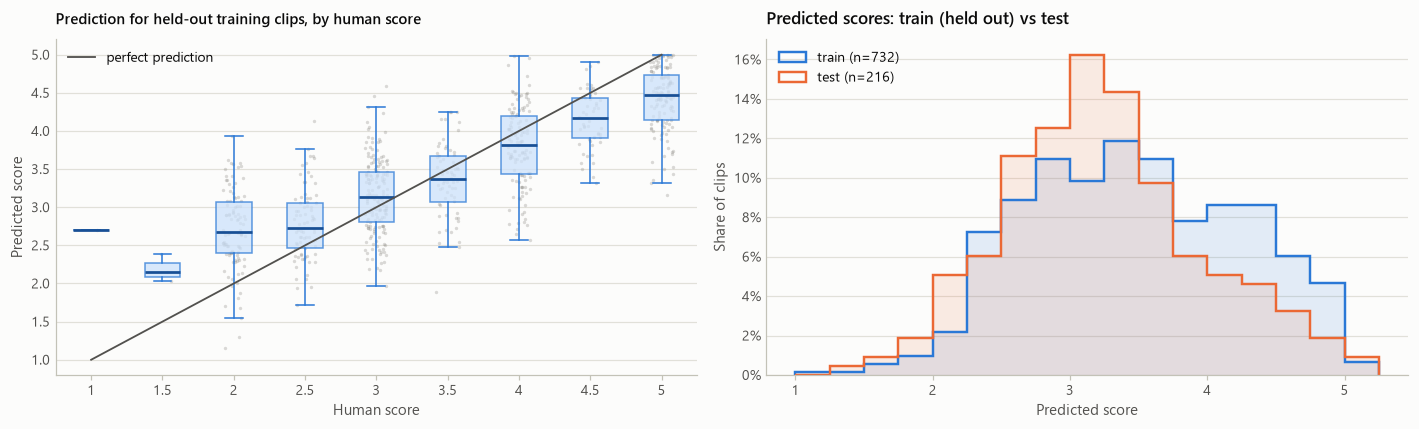

In [40]:
test_rows = table[table["split"] == "test"].reset_index(drop=True)
test_pred = np.clip(final_model.predict(test_rows), 0, 5)
test_pred = np.where(test_rows["noise_bed"], 0.0, test_pred)            # guard from section 5; no test clip matches it

submission = test_df[["filename"]].merge(pd.DataFrame({"filename": test_rows["filename"], "label": np.round(test_pred, 3)}), on="filename", how="left")
assert len(submission) == len(test_df) and submission["label"].notna().all() and list(submission["filename"]) == list(test_df["filename"])
SUBMISSION = PROJECT_DIR / "submission.csv"
submission.to_csv(SUBMISSION, index=False)
print(f"Saved {SUBMISSION.name}: {len(submission)} rows, columns {list(submission.columns)}")
display(submission.head())

# Do the test predictions look like what Part 1 led us to expect?
scored_view = scored.assign(pred=held_out_pred[FINAL])
test_view = test_rows.assign(pred=test_pred)
by_length = pd.DataFrame({
    "train: clips": scored_view.groupby("length_group").size(),
    "train: mean human score": scored_view.groupby("length_group")["label"].mean(),
    "train: mean prediction (held out)": scored_view.groupby("length_group")["pred"].mean(),
    "test: clips": test_view.groupby("length_group").size(),
    "test: mean prediction": test_view.groupby("length_group")["pred"].mean(),
})
display(by_length.style.format({c: "{:.2f}" for c in by_length.columns if "mean" in c}))
print(f"Mean predicted test score: {test_pred.mean():.2f} (Part 1 expected about {reweighted:.2f} from the mix of clip lengths) | "
      f"range {test_pred.min():.2f} to {test_pred.max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
box_by_score(axes[0], scored_view, "pred", "Prediction for held-out training clips, by human score")
levels = sorted(scored_view["label"].unique())
axes[0].plot(range(len(levels)), levels, color=INK2, lw=1.2, zorder=3, label="perfect prediction")
axes[0].set_xlabel("Human score"); axes[0].set_ylabel("Predicted score"); axes[0].legend(loc="upper left")
split_hist(axes[1], pd.concat([scored_view[["split", "pred"]], test_view[["split", "pred"]]]), "pred", np.arange(1, 5.26, 0.25),
           "Predicted score", "Predicted scores: train (held out) vs test")
axes[1].set_ylabel("Share of clips"); axes[1].legend(loc="upper left")
fig.tight_layout()
save(fig, "09_model_predictions")

## 19. Findings of Part 3, limits and next improvements

**The result**

| | Error (RMSE) | Correlation (Pearson r) |
|---|---|---|
| Always guess the average | 1.01 | - |
| Best single feature (Whisper confidence) | 0.83 | 0.58 |
| **Final model (stack of four)** | **0.63** | **0.78** |
| Final model, 45-second clips only | 0.68 | 0.66 |
| Final model, re-weighted to the test mix of clip lengths | 0.66 | |

- **The model cuts the error by 38 %** compared with guessing the average: its predictions are typically 0.63 points from the human score, against 1.01.
- **The error to expect on the test set is about 0.66**, not 0.63. Test is mostly 45-second clips, and the model is weaker on those (0.68 against 0.62 on 60-second clips).
- **Every piece earned its place.** The best single model reaches 0.69; combining the four brings it to 0.63. The stack gives them similar weights (0.23 to 0.37), which means each carries information the others lack.
- **What the model relies on most:** Whisper's word confidence, the clip type (45-second clips are predicted lower), vocabulary variety and speaking rate.
- **Predictions are pulled towards the middle** (left chart in section 18). Clips that humans scored 2 are predicted around 2.7, and clips scored 5 around 4.5. That is normal for a model trained on noisy labels, and it means the extremes are under-called.
- **The test predictions look as expected:** their mean is 3.23, and Part 1 predicted about 3.25 from the mix of clip lengths alone. They range from 1.35 to 5.00. No test clip set off the noise guard.

**Limits**

1. **The strongest features measure overall spoken proficiency, not grammar alone.** Whisper's confidence mixes pronunciation, fluency and grammar. The model predicts the human score well, but it does not detect grammar errors as such.
2. **There is no direct grammar-error feature yet.** The usual rule-based checker (LanguageTool) needs Java, which is not installed on this machine.
3. **We do not know whether one speaker recorded several clips.** If so, the cross-validated error is somewhat optimistic.
4. **The labels are noisy.** Part 1 estimated about half a point of rater disagreement, so an error far below 0.5 is probably not reachable by any model.
5. **45-second clips are the weak spot:** only 149 of them in training, yet they are 65 % of test.
6. **Fillers and true pauses are not measured** (Part 2). Hesitation is represented only by the share of unusually long words.
7. **Do not read single coefficients on their own.** Correlated features share their weight in a ridge model, so the sign of a secondary feature (for example `low_conf_share` next to `asr_word_conf`) can flip.

**Next improvements, most valuable first**

1. **Grammar-error features** from a grammar-correction model: how many corrections it makes per 100 words. This is the most direct measure of what is being scored.
2. **Audio embeddings** from the Whisper encoder or wav2vec2, to capture pronunciation and fluency directly from the sound.
3. **Real pauses** from a voice-activity detector on the cleaned audio.
4. **More weight on 45-second clips** during training, since they dominate the test set.

**What Part 3 produced**

| File | Content |
|---|---|
| `submission.csv` (project folder) | 216 rows, `filename,label`, in the order of `test.csv` |
| `working/features/cv_results.csv` | The model comparison table of section 17 |
| `working/features/text_embeddings.npy` | The text embedding of every transcript |

**To reproduce:** run this notebook from top to bottom with the "Python (SSHL .venv)" kernel. Steps whose results are already saved are skipped, so the 77-minute transcription only runs if its result file is missing. A full re-run with everything cached takes about 5 minutes, most of it the model comparison.